# Part A: Supervised Learning: predicting state Median AQI from energy profiles

**Questions:** Can a state's energy production and consumption profile predict its annual Median AQI? Do the energy clusters from Part B improve the model? Models are trained on 1980–2019 and tested once on 2020–2024.

**Outline**
1. Setup
2. Preprocessing: energy features and the AQI target
3. Validation design and metrics
4. Feature sets
5. Models, baselines and tuning
6. Results: cross-validation and the held-out test set
7. In-depth evaluation of the best model: feature importance, ablation, sensitivity, tradeoffs
8. Failure analysis
9. Summary (generated from the outputs)

Claims about the data or results are followed by the code that checks them. "Reading this" notes interpret the output directly above them.

## 1. Setup
Libraries, settings and data. `N_JOBS` (parallel jobs for tuning) is chosen from the computer's cores and free memory. The state AQI target is built in `AQI_Cleaning.ipynb`.

In [3]:
import os
# Limit each process to one math thread. Must run before numpy/sklearn are imported; parallelism comes from N_JOBS instead.
os.environ.setdefault("OMP_NUM_THREADS", "1")
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # Lasso at tiny alphas; results are still checked by CV
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [4]:
# ---- Settings ----
SEED = 42

# Parallel jobs for tuning: as many as the CPU cores and free memory allow (about 0.3 GB per worker).
# Override by setting the N_JOBS environment variable before starting Jupyter, e.g. N_JOBS=2 on a small laptop.
def pick_n_jobs(gb_per_worker=0.3):
    import joblib
    cores = joblib.cpu_count(only_physical_cores=True)
    try:
        import psutil
        by_memory = int(psutil.virtual_memory().available / 1e9 / gb_per_worker)
    except ImportError:                       # psutil missing: play it safe
        by_memory = max(1, cores // 2)
    return max(1, min(cores, by_memory))

N_JOBS = int(os.environ.get("N_JOBS", pick_n_jobs()))
print(f"using {N_JOBS} parallel jobs")
FIRST_YEAR, LAST_YEAR = 1980, 2024        # years covered by both SEDS and AQI
TEST_START = 2020                         # 2020-2024 held out (as stated in the proposal)
CV_BLOCKS = [(1995, 1999), (2000, 2004), (2005, 2009), (2010, 2014), (2015, 2019)]   # forward-chaining validation blocks

ID_COLS = ["State", "Year"]
POP_COL = "TPOPP"                         # population, thousands of people
CLUSTER_COL = "cluster_id"                # from Unsupervised_Learning.ipynb (one cluster per state)
TARGET_COL = "Median AQI"

# Results tables: add a 'state+year (no energy)' reference row. Set to False to remove it everywhere.
INCLUDE_NO_ENERGY_REFERENCE = True

SEDS_CSV, SEDS_CATEGORIES_XLSX = "df_seds_state_clusters.csv", "SEDS_categories.xlsx"
AQI_TARGET_CSV = "AQI_state_target.csv"     # state-year Median AQI from qualifying counties, built in AQI_Cleaning.ipynb (see 2.5)

ENERGY_CODES = {"BD": "Biodiesel", "B1": "Renewable diesel", "CL": "Coal", "EM": "Fuel ethanol",
                "NG": "Natural gas", "NU": "Nuclear", "PA": "Petroleum", "WW": "Wood and waste",
                "RE": "Non-combustible renewables"}
SECTOR_CODES = {"AC": "Transportation", "CC": "Commercial", "EI": "Electric power", "EG": "Electric power",
                "IC": "Industrial", "RC": "Residential", "PR": "Production", "MP": "Production", "FD": "Production"}

# Chart colors (validated categorical palette: slot 1 blue, slot 2 orange) and quiet axes
BLUE, ORANGE, GRAY, INK, INK2 = "#2a78d6", "#eb6834", "#a3a29b", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRAY,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.titlecolor": INK,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "figure.dpi": 110,
                     "font.size": 16, "axes.titlesize": 18, "axes.labelsize": 16, "xtick.labelsize": 15,
                     "ytick.labelsize": 15, "legend.fontsize": 15, "figure.titlesize": 19})

using 12 parallel jobs


In [5]:
# Data location: works in Colab, from the repo root, or from Notebooks/
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/gdrive")
    INPUT_DIR = Path("/content/gdrive/MyDrive/SIADS_696_Milestone_II/Datasets/EIA_files")
else:
    INPUT_DIR = Path.cwd()
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Datasets").is_dir()), Path.cwd())

def load_file(filename, subdir, reader=pd.read_csv, **kwargs):
    candidates = [INPUT_DIR / filename, INPUT_DIR / "Datasets" / subdir / filename, REPO_ROOT / "Datasets" / subdir / filename]
    for path in candidates:
        if path.exists():
            return reader(path, **kwargs)
    raise FileNotFoundError(f"{filename} not found in {[str(p) for p in candidates]}")

seds_raw = load_file(SEDS_CSV, "SEDS")
seds_categories = load_file(SEDS_CATEGORIES_XLSX, "SEDS", reader=pd.read_excel)
aqi_target = load_file(AQI_TARGET_CSV, "AQI", float_precision="round_trip")   # exact floats, so results match an in-memory build

for name, d in [("SEDS", seds_raw), ("AQI (state target)", aqi_target)]:
    print(f"{name:18s} rows={len(d):6d}  cols={d.shape[1]:3d}  years={d.Year.min()}-{d.Year.max()}  states={d.State.nunique()}")

SEDS               rows=  3315  cols= 57  years=1960-2024  states=51
AQI (state target) rows=  2254  cols=  9  years=1980-2024  states=51


## 2. Preprocessing
Steps, matching the numbered code cells below:
1. **2.1 Align years and states.** SEDS starts in 1960 and AQI in 1980. Both use two-letter state codes (SEDS natively; the AQI target because `AQI_Cleaning.ipynb` converts the EPA's state names). SEDS is used as-is.
2. **2.2 Combine non-combustible renewables** (hydro, solar, wind, geothermal) into one `RE` source per sector. They emit no air pollutants when generating, so for AQI they play the same role, and combining removes many sparse columns.
3. **2.3 Per-capita, then `log1p`.** Dividing by population removes state size (CA vs WY); `log1p` compresses the long right tail and keeps zeros at zero. The few negative values (net consumption at hydro or nuclear plants) are checked to stay above −1, where `log1p` is defined.
4. **2.4 Drop uninformative columns:** columns that are non-zero in under 1% of rows, and near-copies (|r| ≥ 0.98) of another column. These rules look at the data, so they're fit on **training years only** and run after 2.2 to catch duplicates the combining creates.
5. **2.5 The AQI target**, built from qualifying counties.
6. **2.6 Model frame:** target + energy features + previous-year AQI, split into training (1981–2019) and test (2020–2024) rows.

Units: SEDS is in billion Btu and population in thousands, so per-capita values are **million Btu per person**.

In [7]:
def energy_columns(df):
    return [c for c in df.columns if c not in ID_COLS + [POP_COL, CLUSTER_COL, TARGET_COL]]

# 2.1 Align years (states are already two-letter codes in both SEDS and the AQI target)
seds = seds_raw[seds_raw.Year.between(FIRST_YEAR, LAST_YEAR)].copy()
print("SEDS states with no AQI target:", set(seds.State) - set(aqi_target.State), "| AQI target states not in SEDS:", set(aqi_target.State) - set(seds.State))
seds_pairs, aqi_pairs = set(zip(seds.State, seds.Year)), set(zip(aqi_target.State, aqi_target.Year))
missing = pd.DataFrame(sorted(seds_pairs - aqi_pairs), columns=ID_COLS)
print(f"SEDS state-years with no AQI target value ({len(missing)}, dropped by the merge; see AQI_Cleaning.ipynb section 4):",
      missing.groupby("State").Year.agg(lambda y: f"{y.min()}-{y.max()}").to_dict())
print("AQI target state-years with no SEDS value:", len(aqi_pairs - seds_pairs))

SEDS states with no AQI target: set() | AQI target states not in SEDS: set()
SEDS state-years with no AQI target value (41, dropped by the merge; see AQI_Cleaning.ipynb section 4): {'AK': '1982-1987', 'ID': '1980-1992', 'MT': '1984-1987', 'SD': '1980-1998', 'WY': '1980-1986'}
AQI target state-years with no SEDS value: 0


In [8]:
# 2.2 Combine non-combustible renewables into RE<sector>
def combine_renewables(df, categories):
    """Sum all 'Non-Combustible' sources per sector into RE<sector>; EG->EI and MP/FD->PR so sectors line up."""
    category2 = dict(zip(categories["MSN Code"], categories["Category 2"]))
    combined = {}
    for col in energy_columns(df):
        if category2.get(col) == "Non-Combustible":
            sector = {"EG": "EI", "MP": "PR", "FD": "PR"}.get(col[2:4], col[2:4])
            new_col = "RE" + sector + col[4:]
            combined[new_col] = combined.get(new_col, 0) + df[col]
        else:
            combined[col] = df[col]
    return pd.concat([df[ID_COLS + [POP_COL, CLUSTER_COL]], pd.DataFrame(combined, index=df.index)], axis=1)

missing_categories = [c for c in energy_columns(seds) if c not in set(seds_categories["MSN Code"])]
print("energy columns missing from the categories file (would silently count as combustible):", missing_categories)
seds = combine_renewables(seds, seds_categories)
print("energy columns after combining:", len(energy_columns(seds)))

energy columns missing from the categories file (would silently count as combustible): []
energy columns after combining: 40


In [9]:
# 2.3 Per-capita (million Btu per person), then log1p
per_capita = seds[energy_columns(seds)].div(seds[POP_COL], axis=0)
print("negative per-capita values:", int((per_capita < 0).sum().sum()), "| minimum:", round(per_capita.min().min(), 3),
      "| all > -1 (log1p defined):", bool((per_capita > -1).all().all()))
seds[energy_columns(seds)] = np.log1p(per_capita)

negative per-capita values: 33 | minimum: -0.391 | all > -1 (log1p defined): True


In [10]:
# 2.4 Column rules fit on TRAINING years only, then applied to all years
def fit_column_rules(train_df, sparse_threshold=0.01, corr_threshold=0.98):
    """Return {column: reason} for columns to drop. Uses only the rows passed in (training years)."""
    cols = energy_columns(train_df)
    drop = {}
    nonzero_share = (train_df[cols] != 0).mean()
    for c in cols:
        if nonzero_share[c] < sparse_threshold:
            drop[c] = f"non-zero in {nonzero_share[c]:.1%} of training rows"
    kept = [c for c in cols if c not in drop]
    corr = train_df[kept].corr().abs()
    for i, a in enumerate(kept):
        if a in drop:
            continue
        for b in kept[i + 1:]:
            if b not in drop and corr.loc[a, b] >= corr_threshold:
                drop[b] = f"|r| = {corr.loc[a, b]:.3f} with {a}"
    return drop

dropped = fit_column_rules(seds[seds.Year < TEST_START])
dropped_if_all_years = fit_column_rules(seds)          # what the same rules would drop if they could see the test years
print("dropped only because the rules use training years:", sorted(set(dropped) - set(dropped_if_all_years)))
print("dropped only if the rules also see test years:", sorted(set(dropped_if_all_years) - set(dropped)))
pd.Series(dropped, name="reason").to_frame()

dropped only because the rules use training years: ['B1ACB', 'BDCCB', 'BDRCB']
dropped only if the rules also see test years: []


,reason
B1ACB,non-zero in 0.6% of training rows
BDCCB,non-zero in 0.8% of training rows
BDRCB,non-zero in 0.8% of training rows
CLACB,non-zero in 0.0% of training rows
REPRB,|r| = 0.989 with REEIB
NUPRB,|r| = 1.000 with NUEGB


**Fuels that appear after 2000.** Biodiesel and renewable diesel columns are zero in every state until a fuel first appears (years below). A non-zero value therefore also signals "a recent year", so the model could use these columns as a clock rather than as fuel use. The ablation (7.2) tests this group directly.

In [12]:
seds = seds.drop(columns=list(dropped))
ENERGY = energy_columns(seds)
seds_train_years = seds[seds.Year < TEST_START]
first_nonzero = {c: int(seds_train_years.loc[seds_train_years[c] != 0, "Year"].min()) for c in ENERGY}
LATE_FUELS = sorted(c for c, y in first_nonzero.items() if y > 2000)
print(f"{len(ENERGY)} energy features kept")
print("features that are zero everywhere until after 2000:", {c: first_nonzero[c] for c in LATE_FUELS})

34 energy features kept
features that are zero everywhere until after 2000: {'B1PRB': 2011, 'BDACB': 2001, 'BDEIB': 2006, 'BDFDB': 2001}


### 2.5 The state AQI target
The target is each state's annual **Median AQI**, built in `AQI_Cleaning.ipynb` from the EPA's AQI-by-county files: the average of the state's county Median AQI values, weighted by days with AQI, using only **qualifying** county-years:
* **at least 180 days with an AQI value.** Shorter coverage is mostly particulate monitors that sample only some days, and those county-years sit far from their state's median (`AQI_Cleaning.ipynb` 3.1);
* **ozone or PM2.5 the main pollutant on at least one day.** Without either, a county most likely monitors only CO, NO2 or PM10, which read much lower, so its AQI reflects missing monitors rather than cleaner air (3.2).

Excluded county-years are far more common in early years (3.4), so including them would add a monitoring-network trend that the model could mistake for a real effect. State-years with no qualifying county are dropped.

The file also carries `n_counties` (qualifying counties per state-year) and main-pollutant day counts, used in sections 7 and 8.

In [14]:
print(f"state-years: {len(aqi_target)} ({aqi_target.Year.min()}-{aqi_target.Year.max()}, {aqi_target.State.nunique()} states)")
print("qualifying counties per state-year: min", aqi_target.n_counties.min(), "| median", int(aqi_target.n_counties.median()), "| max", aqi_target.n_counties.max())
aqi_target[[TARGET_COL, "n_counties"]].describe().round(2)

state-years: 2254 (1980-2024, 51 states)
qualifying counties per state-year: min 1 | median 11 | max 53


,Median AQI,n_counties
count,2254.00,2254.00
mean,41.84,13.96
std,6.70,10.99
min,18.00,1.00
25%,37.80,5.00
50%,41.88,11.00
75%,45.68,20.00
max,73.92,53.00


In [15]:
# 2.6 Model frame: target + energy features + previous-year AQI + number of qualifying counties
def build_frame(target_table):
    d = target_table[ID_COLS + [TARGET_COL, "n_counties"]].merge(seds, on=ID_COLS, how="left")
    assert d[ENERGY].notna().all().all(), "every AQI state-year should have SEDS data"
    prev = target_table[ID_COLS + [TARGET_COL]].assign(Year=target_table.Year + 1).rename(columns={TARGET_COL: "AQI_lag1"})
    d = d.merge(prev, on=ID_COLS, how="left")          # merged on Year-1, so a gap in years gives NaN, not a wrong lag
    return d.dropna(subset=["AQI_lag1"]).sort_values(ID_COLS).reset_index(drop=True)

df = build_frame(aqi_target)
print(f"dropped {len(aqi_target) - len(df)} state-years with no previous-year AQI (each state's first year, plus the year after a gap) "
      "so every feature set uses identical rows")
print("rows with missing lag in test years:", int(df.loc[df.Year >= TEST_START, "AQI_lag1"].isna().sum()))

train = df[df.Year < TEST_START].reset_index(drop=True)
test = df[df.Year >= TEST_START].reset_index(drop=True)
y_train, y_test = train[TARGET_COL], test[TARGET_COL]
print(f"train: {len(train)} rows ({train.Year.min()}-{train.Year.max()}) | test: {len(test)} rows ({test.Year.min()}-{test.Year.max()})")

dropped 55 state-years with no previous-year AQI (each state's first year, plus the year after a gap) so every feature set uses identical rows
rows with missing lag in test years: 0
train: 1944 rows (1981-2019) | test: 255 rows (2020-2024)


## 3. Validation design and metrics
**Forward-chaining cross-validation.** The task is predicting *future* years from past ones, so each fold trains on every year **before** a 5-year block and validates on that block (five blocks, 1995–2019). Shuffled K-fold would train on 2011 and 2013 to predict 2012, which is easier than predicting forward and gives over-optimistic scores; holding out whole states would break the State feature. All states appear in every fold (table below).
* All model families and baselines use the same 5 folds, which gives the mean ± std per model and allows fold-by-fold (paired) comparisons.
* Hyperparameters are tuned on these folds. The 2020–2024 test set is used **once**, after all choices are made.
* The selected model's CV score is slightly optimistic, because it's the best of a grid; the untouched test set checks it.

In [17]:
def forward_folds(years):
    years = np.asarray(years)
    return [(np.where(years < start)[0], np.where((years >= start) & (years <= end))[0]) for start, end in CV_BLOCKS]

FOLDS = forward_folds(train.Year)
pd.DataFrame([{"fold": i, "train years": f"{train.Year[tr].min()}-{train.Year[tr].max()}", "train rows": len(tr),
               "validation years": f"{train.Year[va].min()}-{train.Year[va].max()}", "validation rows": len(va),
               "states in validation unseen in train": len(set(train.State[va]) - set(train.State[tr]))}
              for i, (tr, va) in enumerate(FOLDS)]).set_index("fold")

,train years,train rows,validation years,validation rows,states in validation unseen in train
fold,,,,,
0,1981-1994,674,1995-1999,250,0
1,1981-1999,924,2000-2004,255,0
2,1981-2004,1179,2005-2009,255,0
3,1981-2009,1434,2010-2014,255,0
4,1981-2014,1689,2015-2019,255,0


**Metrics.** **RMSE** (AQI points) is the main metric: it's in the target's units and penalizes large misses, which matter most for air quality. **MAE** shows the typical miss and is less sensitive to outliers. **R²** is reported for completeness but is misleading across periods: AQI varies less after 2010 (standard deviation about 4.6–5.2, against 6.8–7.7 before; table below), so the same RMSE gives a lower R² in recent years.

In [19]:
by_block = df.assign(block=pd.cut(df.Year, [1979, 1994, 1999, 2004, 2009, 2014, 2019, 2024])).groupby("block", observed=True)[TARGET_COL].std()
print("std of Median AQI by period (lower std -> same RMSE gives lower R²):")
by_block.round(2)

std of Median AQI by period (lower std -> same RMSE gives lower R²):


block
(1979, 1994]    7.11
(1994, 1999]    6.90
(1999, 2004]    7.74
(2004, 2009]    6.81
(2009, 2014]    5.16
(2014, 2019]    4.59
(2019, 2024]    5.23
Name: Median AQI, dtype: float64

## 4. Feature sets

| Feature set | Columns | Purpose |
|---|---|---|
| `energy` | per-capita energy features + Year | Pure energy profile; Year captures the national trend |
| `energy+cluster` | + cluster (one-hot) | The proposal's plan: add the Part B clusters |
| `energy+state` | + State (one-hot) | Gives each state its own baseline level (geography, weather, monitor placement) |
| `energy+state+lag` | + previous-year AQI | **Forecasting variant:** answers "next year's AQI", not "AQI from energy", so it's reported separately |
| `state+year (no energy)` | State + Year only | **Reference, not a candidate:** what's achievable with no energy data. Never picked as the best model (`INCLUDE_NO_ENERGY_REFERENCE`) |

State and cluster are never combined: each state is in exactly one cluster, so with State present the clusters add nothing (checked below). Population isn't a feature because the energy features are already per capita.

**Cluster leakage caveat:** `cluster_id` comes from `Unsupervised_Learning.ipynb`, which clustered on **1960–2024** (its printed outputs show `Years : 1960 - 2024` and windows up to 2020), not on data through 2019 as the proposal planned. So `energy+cluster` uses test-period energy data. The leakage contains no AQI, and the clusters add nothing alongside State, so the conclusions don't change, but it should be disclosed or fixed by re-clustering on ≤ 2019.

In [21]:
state_dummies = pd.get_dummies(df["State"], dtype=float)
with_cluster = pd.concat([state_dummies, pd.get_dummies(df[CLUSTER_COL], prefix="cluster", dtype=float)], axis=1)
print("cluster_id constant within each state:", bool((df.groupby("State")[CLUSTER_COL].nunique() == 1).all()))
print("rank of State dummies:", np.linalg.matrix_rank(state_dummies), "| rank of State + cluster dummies:", np.linalg.matrix_rank(with_cluster))

cluster_id constant within each state: True
rank of State dummies: 51 | rank of State + cluster dummies: 51


In [22]:
FEATURE_SETS = {
    "energy":           {"num": ENERGY + ["Year"],              "cat": []},
    "energy+cluster":   {"num": ENERGY + ["Year"],              "cat": [CLUSTER_COL]},
    "energy+state":     {"num": ENERGY + ["Year"],              "cat": ["State"]},
    "energy+state+lag": {"num": ENERGY + ["Year", "AQI_lag1"],  "cat": ["State"]},
}
if INCLUDE_NO_ENERGY_REFERENCE:
    FEATURE_SETS["state+year (no energy)"] = {"num": ["Year"], "cat": ["State"]}
EXPLANATORY_SETS = ["energy", "energy+cluster", "energy+state"]
REFERENCE_SETS = ["state+year (no energy)"] if INCLUDE_NO_ENERGY_REFERENCE else []

def make_pipeline(num, cat, model=None):
    pre = ColumnTransformer([("num", StandardScaler(), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])
    return Pipeline([("pre", pre), ("model", model if model is not None else Ridge())])

## 5. Models, baselines and tuning
### 5.1 Model families
Four families with different mechanisms (the rubric requires at least three):

| Family | Models | Mechanism | Why it fits this problem | Tuned hyperparameters |
|---|---|---|---|---|
| Regularized linear | Ridge, Lasso, ElasticNet | Global linear fit with an L2 / L1 / mixed penalty | Signed, interpretable coefficients; the penalty handles correlated energy features; can extend a trend past 2019 | `alpha`, `l1_ratio` |
| Tree ensembles | Random Forest, Histogram Gradient Boosting | Averaged / boosted decision trees | Nonlinear effects and interactions with no scaling assumptions; can't extrapolate past the training range | depth, leaf size, features per split, learning rate |
| Instance-based | k-Nearest Neighbors | Averages the AQI of the most similar state-years | No assumed functional form: "similar energy profiles, similar AQI" | `k`, distance weighting |
| Kernel | Support Vector Regression (RBF) | Smooth nonlinear function with an ε-insensitive loss | Smooth fit that ignores small target noise | `C`, `gamma`, `epsilon` |

All models share one pipeline: numeric features are standardized and categoricals one-hot encoded inside it, so both are learned from each fold's training rows only. Every family × feature-set combination is tuned with `GridSearchCV` on the forward folds, selecting by RMSE. The Random Forest uses 300 trees throughout.

In [24]:
FAMILIES = {
    "Linear (Ridge/Lasso/ElasticNet)": [
        {"model": [Ridge()], "model__alpha": np.logspace(-3, 4, 29)},
        {"model": [Lasso(max_iter=50_000)], "model__alpha": np.logspace(-4, 1, 21)},
        {"model": [ElasticNet(max_iter=50_000)], "model__alpha": np.logspace(-4, 1, 21), "model__l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9]},
    ],
    "Tree ensemble (RF/HGB)": [
        {"model": [RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=1)],
         "model__max_depth": [None, 10], "model__min_samples_leaf": [1, 5, 20], "model__max_features": [0.3, 0.6, 1.0]},
        {"model": [HistGradientBoostingRegressor(random_state=SEED)],
         "model__learning_rate": [0.03, 0.1], "model__max_depth": [3, None],
         "model__min_samples_leaf": [10, 30], "model__l2_regularization": [0.0, 1.0]},
    ],
    "Instance-based (KNN)": [
        {"model": [KNeighborsRegressor()], "model__n_neighbors": [1, 2, 3, 5, 10, 20, 40], "model__weights": ["uniform", "distance"]},
    ],
    "Kernel (SVR)": [
        {"model": [SVR(kernel="rbf")], "model__C": [1, 10, 100, 1000], "model__gamma": ["scale", 0.0003, 0.001, 0.003, 0.01],
         "model__epsilon": [0.1, 1.0, 2.0, 3.0, 5.0]},
    ],
}
SCORING = {"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"}

In [25]:
def fold_scores(cv_results, i):
    """Per-fold metrics of grid point i, as positive numbers."""
    return {m: np.array([cv_results[f"split{k}_test_{m}"][i] * (1 if m == "r2" else -1) for k in range(len(FOLDS))])
            for m in SCORING}

def n_settings(grid):
    """Number of hyperparameter combinations in a grid (a list of dicts)."""
    return sum(int(np.prod([len(v) for v in g.values()])) for g in grid)

searches, rows = {}, []
t0 = time.time()
n_steps, step = len(FAMILIES) * len(FEATURE_SETS), 0
print(f"tuning {n_steps} family x feature-set combinations with {N_JOBS} parallel jobs")
for family, grid in FAMILIES.items():
    for fs_name, fs in FEATURE_SETS.items():
        step += 1
        print(f"[{step}/{n_steps}] {family} on {fs_name}: {n_settings(grid)} settings x {len(FOLDS)} folds "
              f"= {n_settings(grid) * len(FOLDS)} fits ...", end=" ", flush=True)
        t_start = time.time()
        gs = GridSearchCV(make_pipeline(fs["num"], fs["cat"]), grid, scoring=SCORING, refit="rmse", cv=FOLDS, n_jobs=N_JOBS)
        gs.fit(train, y_train)
        print(f"done in {time.time() - t_start:.0f}s (total {(time.time() - t0) / 60:.1f} min)", flush=True)
        scores = fold_scores(gs.cv_results_, gs.best_index_)
        searches[(family, fs_name)] = gs
        rows.append({"family": family, "feature_set": fs_name,
                     "model": type(gs.best_params_["model"]).__name__,
                     "params": {k.replace("model__", ""): v for k, v in gs.best_params_.items() if k != "model"},
                     **{f"cv_{m}_mean": s.mean() for m, s in scores.items()},
                     **{f"cv_{m}_std": s.std() for m, s in scores.items()},
                     "fit_seconds": gs.cv_results_["mean_fit_time"][gs.best_index_]})
cv_table = pd.DataFrame(rows)
print(f"tuned {len(searches)} family x feature-set combinations in {time.time() - t0:.0f}s")

tuning 20 family x feature-set combinations with 12 parallel jobs
[1/20] Linear (Ridge/Lasso/ElasticNet) on energy: 155 settings x 5 folds = 775 fits ... done in 3s (total 0.1 min)
[2/20] Linear (Ridge/Lasso/ElasticNet) on energy+cluster: 155 settings x 5 folds = 775 fits ... done in 3s (total 0.1 min)
[3/20] Linear (Ridge/Lasso/ElasticNet) on energy+state: 155 settings x 5 folds = 775 fits ... done in 3s (total 0.2 min)
[4/20] Linear (Ridge/Lasso/ElasticNet) on energy+state+lag: 155 settings x 5 folds = 775 fits ... done in 3s (total 0.2 min)
[5/20] Linear (Ridge/Lasso/ElasticNet) on state+year (no energy): 155 settings x 5 folds = 775 fits ... done in 1s (total 0.2 min)
[6/20] Tree ensemble (RF/HGB) on energy: 34 settings x 5 folds = 170 fits ... done in 21s (total 0.6 min)
[7/20] Tree ensemble (RF/HGB) on energy+cluster: 34 settings x 5 folds = 170 fits ... done in 18s (total 0.9 min)
[8/20] Tree ensemble (RF/HGB) on energy+state: 34 settings x 5 folds = 170 fits ... done in 20s (to

### 5.2 Baselines
Scored on the same folds; a model is only useful if it beats them:
* **Mean of training years** and **state mean**: the simplest level predictions.
* **Persistence:** each state's average over its last 3 training years, held fixed for the whole block. This is the main benchmark for the explanatory models, because like them it uses no AQI from inside the years it predicts.
* **Naive forecast:** last year's actual AQI. A benchmark for the forecasting variant only, since it uses AQI from inside the predicted period.
* **Unregularized OLS** (`LinearRegression`, same pipeline) on every feature set: shows how much the linear models' penalty helps. Never eligible as the best model.

In [27]:
def baseline_predictions(train_part, target_part):
    last3 = train_part.sort_values("Year").groupby("State")[TARGET_COL].apply(lambda s: s.tail(3).mean())
    return {"Mean of training years": np.full(len(target_part), train_part[TARGET_COL].mean()),
            "State mean (all training years)": target_part.State.map(train_part.groupby("State")[TARGET_COL].mean()).values,
            "Persistence: state's last 3 training years": target_part.State.map(last3).values,
            "Naive forecast: previous year's AQI": target_part["AQI_lag1"].values}

def metric_dict(y, p):
    return {"rmse": root_mean_squared_error(y, p), "mae": mean_absolute_error(y, p), "r2": r2_score(y, p)}

per_fold = {}
for tr, va in FOLDS:
    for name, p in baseline_predictions(train.iloc[tr], train.iloc[va]).items():
        per_fold.setdefault(name, []).append(metric_dict(y_train.iloc[va], p))
baseline_cv = pd.DataFrame([{"baseline": n, **{f"cv_{m}_mean": np.mean([f[m] for f in folds]) for m in SCORING},
                             **{f"cv_{m}_std": np.std([f[m] for f in folds]) for m in SCORING}} for n, folds in per_fold.items()])

In [28]:
# OLS baseline: same pipeline and folds as the tuned models, no penalty and nothing to tune
ols_rows, ols_models = [], {}
for fs_name, fs in FEATURE_SETS.items():
    pipe = make_pipeline(fs["num"], fs["cat"], LinearRegression())
    folds = [metric_dict(y_train.iloc[va], clone(pipe).fit(train.iloc[tr], y_train.iloc[tr]).predict(train.iloc[va])) for tr, va in FOLDS]
    ols_models[fs_name] = clone(pipe).fit(train, y_train)
    ols_rows.append({"baseline": f"OLS ({fs_name})", "feature_set": fs_name,
                     **{f"cv_{m}_mean": np.mean([f[m] for f in folds]) for m in SCORING},
                     **{f"cv_{m}_std": np.std([f[m] for f in folds]) for m in SCORING}})
ols_cv = pd.DataFrame(ols_rows)


In [29]:
# Check: did any search pick a value at the edge of its grid? (an edge pick means the best value may lie outside the grid)
edge_rows = []
for (family, fs_name), gs in searches.items():
    model_type = type(gs.best_params_["model"])
    grid = next(g for g in FAMILIES[family] if isinstance(g["model"][0], model_type))
    for k, v in gs.best_params_.items():
        values = [x for x in grid.get(k, []) if isinstance(x, (int, float)) and x is not None]
        if k != "model" and isinstance(v, (int, float)) and len(values) > 1 and v in (min(values), max(values)):
            edge_rows.append({"family": family, "feature_set": fs_name, "hyperparameter": k.replace("model__", ""), "chosen": v,
                              "edge": "min" if v == min(values) else "max", "grid": values})
edge_df = pd.DataFrame(edge_rows, columns=["family", "feature_set", "hyperparameter", "chosen", "edge", "grid"])
edge_df

,family,feature_set,hyperparameter,chosen,edge,grid
0,Tree ensemble (RF/HGB),energy,max_features,1.0000,max,"[0.3, 0.6, 1.0]"
1,Tree ensemble (RF/HGB),energy,min_samples_leaf,1.0000,min,"[1, 5, 20]"
2,Tree ensemble (RF/HGB),energy+cluster,min_samples_leaf,1.0000,min,"[1, 5, 20]"
3,Tree ensemble (RF/HGB),energy+state,min_samples_leaf,1.0000,min,"[1, 5, 20]"
4,Tree ensemble (RF/HGB),energy+state+lag,max_features,1.0000,max,"[0.3, 0.6, 1.0]"
5,Tree ensemble (RF/HGB),energy+state+lag,min_samples_leaf,20.0000,max,"[1, 5, 20]"
6,Tree ensemble (RF/HGB),state+year (no energy),max_features,0.3000,min,"[0.3, 0.6, 1.0]"
7,Tree ensemble (RF/HGB),state+year (no energy),min_samples_leaf,1.0000,min,"[1, 5, 20]"
8,Kernel (SVR),energy,epsilon,5.0000,max,"[0.1, 1.0, 2.0, 3.0, 5.0]"
9,Kernel (SVR),energy+cluster,epsilon,5.0000,max,"[0.1, 1.0, 2.0, 3.0, 5.0]"


### 5.3 Grid-edge check
**Reading this:** a pick at the edge of a grid can mean the best value lies outside it, unless the edge is a natural limit (`min_samples_leaf=1`, all features). The best explanatory model's only edge pick is `min_samples_leaf=1`, a natural limit (printed again at the end of 6.3).

The SVR grid was widened once (`epsilon` up to 5, `gamma` down to 0.0003) after the first run picked the edge. The explanatory SVRs still pick the largest `epsilon` (5.0, about one standard deviation of the target), so they ignore errors under 5 AQI points. Widening further would push the SVR toward a flat fit, which itself shows that the SVR finds little learnable signal in the energy features.

## 6. Results
### 6.1 Cross-validation: every family × feature set (mean ± std over 5 forward folds)

In [32]:
def pm(mean, std, digits=2):
    return f"{mean:.{digits}f} ± {std:.{digits}f}"

def show_cv(t):
    out = t.copy()
    for m, d in [("rmse", 2), ("mae", 2), ("r2", 3)]:
        out[f"CV {m.upper() if m != 'r2' else 'R²'}"] = [pm(a, b, d) for a, b in zip(t[f"cv_{m}_mean"], t[f"cv_{m}_std"])]
    return out

show_cv(cv_table).pivot(index="family", columns="feature_set", values="CV RMSE")[list(FEATURE_SETS)]

feature_set,energy,energy+cluster,energy+state,energy+state+lag,state+year (no energy)
family,,,,,
Instance-based (KNN),4.56 ± 1.20,4.58 ± 1.19,4.57 ± 1.18,4.47 ± 1.17,3.68 ± 0.60
Kernel (SVR),4.97 ± 1.03,4.99 ± 1.08,4.95 ± 1.10,3.29 ± 0.78,4.38 ± 1.00
Linear (Ridge/Lasso/ElasticNet),5.68 ± 1.04,5.66 ± 0.98,5.68 ± 1.04,2.87 ± 0.53,4.98 ± 0.77
Tree ensemble (RF/HGB),3.84 ± 0.54,3.83 ± 0.58,3.78 ± 0.56,2.99 ± 0.55,3.71 ± 0.63


In [33]:
show_cv(pd.concat([baseline_cv, ols_cv.drop(columns="feature_set")])).set_index("baseline")[["CV RMSE", "CV MAE", "CV R²"]]

,CV RMSE,CV MAE,CV R²
baseline,,,
Mean of training years,6.46 ± 1.21,5.01 ± 0.99,-0.079 ± 0.052
State mean (all training years),4.86 ± 0.63,3.80 ± 0.57,0.357 ± 0.180
Persistence: state's last 3 training years,3.97 ± 0.48,3.07 ± 0.29,0.571 ± 0.100
Naive forecast: previous year's AQI,2.88 ± 0.50,2.17 ± 0.33,0.774 ± 0.058
OLS (energy),9.51 ± 4.05,7.35 ± 3.11,-1.842 ± 2.113
OLS (energy+cluster),11.54 ± 6.49,6.96 ± 2.37,-4.769 ± 7.218
OLS (energy+state),8.28 ± 6.30,4.45 ± 0.93,-2.887 ± 6.260
OLS (energy+state+lag),6.81 ± 4.04,4.01 ± 2.10,-0.898 ± 2.163
OLS (state+year (no energy)),5.16 ± 0.57,4.10 ± 0.52,0.272 ± 0.192


**Reading this:**
* **Tree ensembles are the best explanatory family** (3.78 ± 0.56 on `energy+state`) and the only explanatory model that beats persistence (3.97 ± 0.48) in CV.
* **No explanatory model beats the no-energy reference:** State + Year alone reaches 3.68 ± 0.60 (KNN).
* **Clusters add nothing:** `energy+cluster` scores within 0.02 of `energy` for every family.
* **With last year's AQI**, the best model (linear, 2.87 ± 0.53) only matches the naive forecast (2.88 ± 0.50).
* **Unpenalized OLS is unstable** on the correlated energy features (8.28 ± 6.30 on `energy+state`, against 5.68 ± 1.04 for the tuned linear family); it's stable only without energy features (5.16 ± 0.57).

### 6.2 Best model per family
The explanatory framing (no lagged AQI, the proposal's question) and the forecasting variant answer different questions, so they're compared separately. Within each, every family's feature set and hyperparameters are chosen by mean CV RMSE.

In [36]:
def best_per_family(feature_sets):
    t = cv_table[cv_table.feature_set.isin(feature_sets)]
    return t.loc[t.groupby("family")["cv_rmse_mean"].idxmin()].sort_values("cv_rmse_mean")

best_explanatory = best_per_family(EXPLANATORY_SETS)
best_forecast = best_per_family(["energy+state+lag"])
best_reference = best_per_family(REFERENCE_SETS) if REFERENCE_SETS else cv_table.iloc[0:0]
cols = ["family", "feature_set", "model", "params", "CV RMSE", "CV MAE", "CV R²", "fit_seconds"]
print("Explanatory framing (energy features, no lagged AQI):")
display(show_cv(best_explanatory)[cols].set_index("family"))
print("Forecasting variant (adds previous-year AQI):")
display(show_cv(best_forecast)[cols].set_index("family"))
if len(best_reference):
    print("Reference (State + Year, no energy features):")
    display(show_cv(best_reference)[cols].set_index("family"))

Explanatory framing (energy features, no lagged AQI):


,feature_set,model,params,CV RMSE,CV MAE,CV R²,fit_seconds
family,,,,,,,
Tree ensemble (RF/HGB),energy+state,RandomForestRegressor,"{'max_depth': None, 'max_features': 0.6, 'min_...",3.78 ± 0.56,2.90 ± 0.33,0.617 ± 0.081,2.453538
Instance-based (KNN),energy,KNeighborsRegressor,"{'n_neighbors': 2, 'weights': 'distance'}",4.56 ± 1.20,3.52 ± 1.00,0.436 ± 0.230,0.003220
Kernel (SVR),energy+state,SVR,"{'C': 100, 'epsilon': 5.0, 'gamma': 'scale'}",4.95 ± 1.10,3.87 ± 0.96,0.327 ± 0.243,0.025618
Linear (Ridge/Lasso/ElasticNet),energy+cluster,ElasticNet,"{'alpha': 0.5623413251903491, 'l1_ratio': 0.7}",5.66 ± 0.98,4.43 ± 0.82,0.158 ± 0.119,0.004594


Forecasting variant (adds previous-year AQI):


,feature_set,model,params,CV RMSE,CV MAE,CV R²,fit_seconds
family,,,,,,,
Linear (Ridge/Lasso/ElasticNet),energy+state+lag,Lasso,{'alpha': 0.1778279410038923},2.87 ± 0.53,2.13 ± 0.34,0.778 ± 0.058,0.008356
Tree ensemble (RF/HGB),energy+state+lag,RandomForestRegressor,"{'max_depth': None, 'max_features': 1.0, 'min_...",2.99 ± 0.55,2.26 ± 0.40,0.765 ± 0.041,1.889874
Kernel (SVR),energy+state+lag,SVR,"{'C': 100, 'epsilon': 0.1, 'gamma': 0.0003}",3.29 ± 0.78,2.52 ± 0.59,0.701 ± 0.109,0.098561
Instance-based (KNN),energy+state+lag,KNeighborsRegressor,"{'n_neighbors': 2, 'weights': 'distance'}",4.47 ± 1.17,3.47 ± 0.97,0.456 ± 0.221,0.005590


Reference (State + Year, no energy features):


,feature_set,model,params,CV RMSE,CV MAE,CV R²,fit_seconds
family,,,,,,,
Instance-based (KNN),state+year (no energy),KNeighborsRegressor,"{'n_neighbors': 2, 'weights': 'distance'}",3.68 ± 0.60,2.83 ± 0.35,0.636 ± 0.077,0.002868
Tree ensemble (RF/HGB),state+year (no energy),RandomForestRegressor,"{'max_depth': None, 'max_features': 0.3, 'min_...",3.71 ± 0.63,2.82 ± 0.36,0.631 ± 0.082,0.547978
Kernel (SVR),state+year (no energy),SVR,"{'C': 10, 'epsilon': 3.0, 'gamma': 'scale'}",4.38 ± 1.00,3.35 ± 0.79,0.509 ± 0.088,0.031798
Linear (Ridge/Lasso/ElasticNet),state+year (no energy),ElasticNet,"{'alpha': 0.005623413251903491, 'l1_ratio': 0.1}",4.98 ± 0.77,3.94 ± 0.68,0.340 ± 0.118,0.007712


### 6.3 Held-out test set (2020–2024), used once
Each family's chosen configuration is refit on all training years (`GridSearchCV` does this automatically) and scored on 2020–2024, alongside the baselines.

In [38]:
test_rows = []
for framing, table in [("explanatory", best_explanatory), ("forecasting", best_forecast), ("reference", best_reference)]:
    for _, r in table.iterrows():
        model = searches[(r.family, r.feature_set)].best_estimator_
        test_rows.append({"framing": framing, "family": r.family, "feature_set": r.feature_set,
                          "cv_rmse": r.cv_rmse_mean, **{f"test_{k}": v for k, v in metric_dict(y_test, model.predict(test)).items()}})
for name, p in baseline_predictions(train, test).items():
    test_rows.append({"framing": "baseline", "family": name, "feature_set": "-",
                      "cv_rmse": baseline_cv.set_index("baseline").loc[name, "cv_rmse_mean"],
                      **{f"test_{k}": v for k, v in metric_dict(y_test, p).items()}})
for _, r in ols_cv.iterrows():
    test_rows.append({"framing": "baseline (OLS)", "family": r.baseline, "feature_set": r.feature_set, "cv_rmse": r.cv_rmse_mean,
                      **{f"test_{k}": v for k, v in metric_dict(y_test, ols_models[r.feature_set].predict(test)).items()}})
test_table = pd.DataFrame(test_rows)
test_table.round(3)

,framing,family,feature_set,cv_rmse,test_rmse,test_mae,test_r2
0,explanatory,Tree ensemble (RF/HGB),energy+state,3.780,3.078,2.317,0.652
1,explanatory,Instance-based (KNN),energy,4.561,3.125,2.241,0.641
2,explanatory,Kernel (SVR),energy+state,4.954,3.991,3.216,0.415
3,explanatory,Linear (Ridge/Lasso/ElasticNet),energy+cluster,5.662,5.157,3.866,0.023
4,forecasting,Linear (Ridge/Lasso/ElasticNet),energy+state+lag,2.865,2.665,2.082,0.739
5,forecasting,Tree ensemble (RF/HGB),energy+state+lag,2.993,2.652,2.066,0.742
6,forecasting,Kernel (SVR),energy+state+lag,3.287,2.680,2.074,0.736
7,forecasting,Instance-based (KNN),energy+state+lag,4.470,3.008,2.179,0.668
8,reference,Instance-based (KNN),state+year (no energy),3.684,2.442,1.873,0.781
9,reference,Tree ensemble (RF/HGB),state+year (no energy),3.710,2.460,1.840,0.778


In [39]:
# The model analysed in depth: best explanatory model by CV RMSE (the proposal's question)
BEST = best_explanatory.iloc[0]
BEST_SEARCH = searches[(BEST.family, BEST.feature_set)]
best_model = BEST_SEARCH.best_estimator_
BEST_NUM, BEST_CAT = FEATURE_SETS[BEST.feature_set]["num"], FEATURE_SETS[BEST.feature_set]["cat"]
test_pred = best_model.predict(test)
print(f"Best explanatory model: {BEST.model} ({BEST.family}) on '{BEST.feature_set}', params={BEST.params}")
print(f"CV RMSE {pm(BEST.cv_rmse_mean, BEST.cv_rmse_std)} | test RMSE {root_mean_squared_error(y_test, test_pred):.2f}")
tt = test_table.set_index("family")
p_name = "Persistence: state's last 3 training years"
print(f"Persistence baseline: CV RMSE {tt.loc[p_name, 'cv_rmse']:.2f} | test RMSE {tt.loc[p_name, 'test_rmse']:.2f}")
print("Explanatory models beating persistence on CV:", list(best_explanatory.family[best_explanatory.cv_rmse_mean < tt.loc[p_name, 'cv_rmse']]))
pers_test = tt.loc[p_name, "test_rmse"]
print("Explanatory models beating persistence on test:",
      list(test_table[(test_table.framing == "explanatory") & (test_table.test_rmse < pers_test)].family))

# Paired comparison on the same folds: is the gap to persistence bigger than fold-to-fold noise?
model_fold_rmse = fold_scores(BEST_SEARCH.cv_results_, BEST_SEARCH.best_index_)["rmse"]
pers_fold_rmse = np.array([f["rmse"] for f in per_fold[p_name]])
gap = model_fold_rmse - pers_fold_rmse
print(f"per-fold RMSE, model minus persistence: {np.round(gap, 2)} -> model better in {int((gap < 0).sum())} of {len(gap)} folds")

if len(best_reference):
    ref = best_reference.iloc[0]
    print(f"Reference without energy ({ref.family}): CV RMSE {pm(ref.cv_rmse_mean, ref.cv_rmse_std)} vs best explanatory {pm(BEST.cv_rmse_mean, BEST.cv_rmse_std)}")

best_edges = edge_df[(edge_df.family == BEST.family) & (edge_df.feature_set == BEST.feature_set)]
print("edge-of-grid picks for this model:", best_edges[["hyperparameter", "chosen", "edge"]].to_dict("records") or "none")

Best explanatory model: RandomForestRegressor (Tree ensemble (RF/HGB)) on 'energy+state', params={'max_depth': None, 'max_features': 0.6, 'min_samples_leaf': 1}
CV RMSE 3.78 ± 0.56 | test RMSE 3.08
Persistence baseline: CV RMSE 3.97 | test RMSE 2.69
Explanatory models beating persistence on CV: ['Tree ensemble (RF/HGB)']
Explanatory models beating persistence on test: []
per-fold RMSE, model minus persistence: [-0.14 -0.11 -0.06 -0.46 -0.2 ] -> model better in 5 of 5 folds
Reference without energy (Instance-based (KNN)): CV RMSE 3.68 ± 0.60 vs best explanatory 3.78 ± 0.56
edge-of-grid picks for this model: [{'hyperparameter': 'min_samples_leaf', 'chosen': 1.0, 'edge': 'min'}]


### 6.4 The best explanatory model
**Reading the lines above:** the Random Forest on `energy+state` beats persistence in all 5 CV folds but **not on the test set** (3.08 against 2.69), and the no-energy reference does better on test (2.44). Below: its test predictions against actual values, and its errors by state.

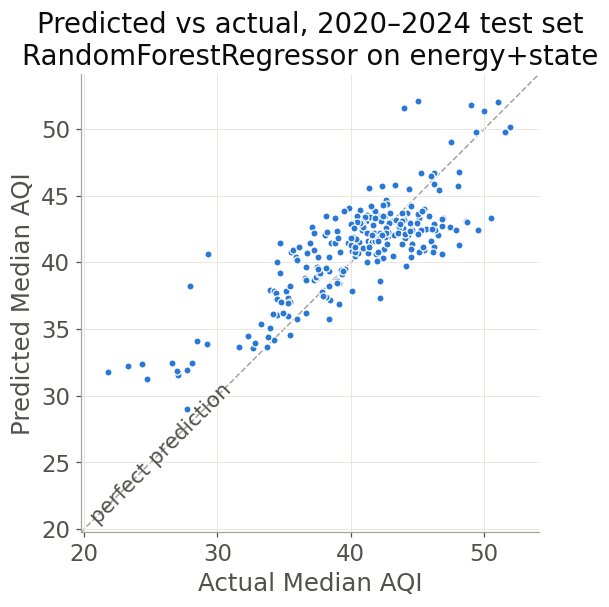

In [41]:
fig, ax = plt.subplots(figsize=(6, 5.8))
lo, hi = min(y_test.min(), test_pred.min()) - 2, max(y_test.max(), test_pred.max()) + 2
ax.plot([lo, hi], [lo, hi], color=GRAY, lw=1, ls="--", zorder=1)
ax.text(lo + 1.5, lo + 0.3, "perfect prediction", color=INK2, ha="left", va="bottom", fontsize=14, rotation=45, rotation_mode="anchor")
ax.scatter(y_test, test_pred, s=22, color=BLUE, edgecolor="white", linewidth=0.8, zorder=2)
ax.set(xlim=(lo, hi), ylim=(lo, hi), xlabel="Actual Median AQI", ylabel="Predicted Median AQI",
       title=f"Predicted vs actual, 2020–2024 test set\n{BEST.model} on {BEST.feature_set}")
ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [42]:
# Error by state on the test set (proposal deliverable)
err = test.assign(pred=test_pred, residual=y_test - test_pred)
by_state = err.groupby("State").agg(test_rmse=("residual", lambda r: np.sqrt((r ** 2).mean())),
                                    mean_residual=("residual", "mean"),
                                    same_sign_all_years=("residual", lambda r: bool((r > 0).all() or (r < 0).all())))
by_state.sort_values("test_rmse", ascending=False).round(2).head(15)

,test_rmse,mean_residual,same_sign_all_years
State,,,
HI,7.59,-6.95,True
NE,6.60,-6.01,True
MT,5.17,-3.24,False
OK,4.94,4.60,True
DC,4.87,-3.97,True
AK,4.80,-4.77,True
AZ,4.54,4.06,True
KS,4.08,3.25,False
RI,4.07,-3.09,False


**Reading this:** errors are concentrated in a few states with consistent misses: Hawaii and Nebraska are over-predicted in every test year (mean error about −7 and −6), while Oklahoma, Arizona and Colorado are under-predicted every year. Section 8 examines why.

## 7. In-depth evaluation of the best model
### 7.1 Feature importance
#### 7.1a Permutation importance (grouped, on the test set)
Permutation importance measures how much test RMSE rises when a feature's values are shuffled across rows, breaking its link to the target. It works the same way for any model, and it reflects prediction accuracy rather than how often a feature is used. Features are shuffled in **groups** (all columns of one fuel, or of one sector) because the energy columns are correlated: shuffling one column at a time would understate a fuel whose information is spread across several columns. State is shuffled as a single column.

In [45]:
def group_permutation_importance(model, X, y, groups, n_repeats=30, seed=SEED):
    rng = np.random.default_rng(seed)
    base = root_mean_squared_error(y, model.predict(X))
    out = []
    for g, cols in groups.items():
        increases = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            increases.append(root_mean_squared_error(y, model.predict(Xp)) - base)
        out.append({"group": g, "n_cols": len(cols), "rmse_increase": np.mean(increases), "std": np.std(increases)})
    return pd.DataFrame(out).sort_values("rmse_increase", ascending=False).reset_index(drop=True)

by_source = {ENERGY_CODES.get(p, p): [c for c in ENERGY if c[:2] == p] for p in sorted({c[:2] for c in ENERGY})}
by_sector = {}
for c in ENERGY:
    by_sector.setdefault(SECTOR_CODES.get(c[2:4], c[2:4]), []).append(c)
context = {c: [c] for c in ["Year"] + BEST_CAT}

imp_source = group_permutation_importance(best_model, test, y_test, {**by_source, **context})
imp_sector = group_permutation_importance(best_model, test, y_test, {**by_sector, **context})
imp_single = group_permutation_importance(best_model, test, y_test, {c: [c] for c in BEST_NUM + BEST_CAT}, n_repeats=10).head(12)
display(imp_source.round(3))
print("test years:", sorted(test.Year.unique()), "| last training year:", train.Year.max())

,group,n_cols,rmse_increase,std
0,Natural gas,6,1.194,0.067
1,Petroleum,6,0.910,0.083
2,Non-combustible renewables,4,0.896,0.114
3,Wood and waste,4,0.433,0.040
4,State,1,0.330,0.070
5,Coal,5,0.287,0.041
6,Nuclear,1,0.077,0.020
7,Fuel ethanol,4,0.067,0.015
8,Biodiesel,3,0.056,0.009
9,Renewable diesel,1,0.001,0.000


test years: [2020, 2021, 2022, 2023, 2024] | last training year: 2019


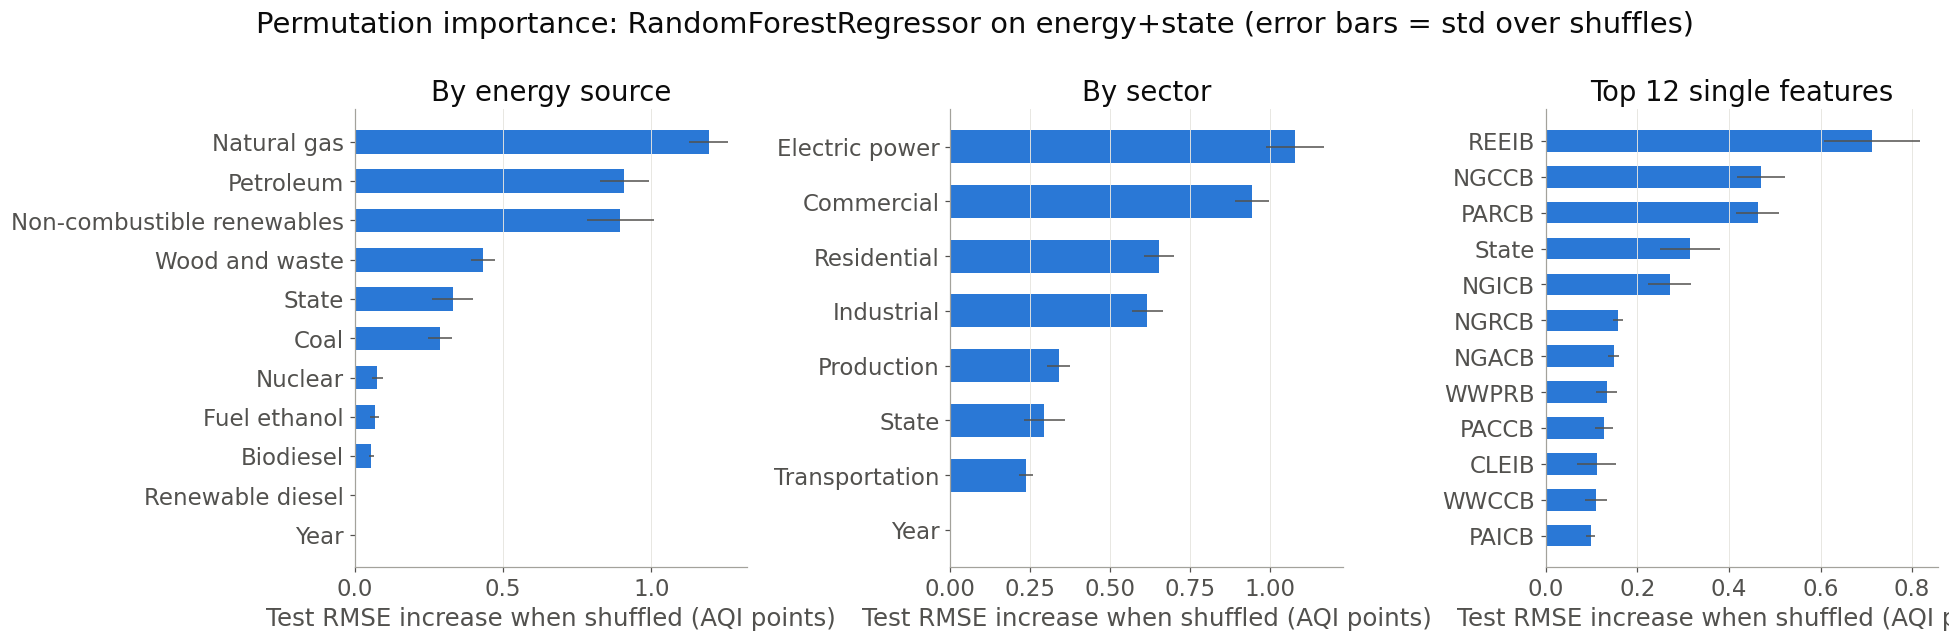

In [46]:
def importance_bar(ax, t, title):
    t = t.iloc[::-1]
    ax.barh(t.group, t.rmse_increase, xerr=t["std"], color=BLUE, height=0.6, error_kw={"ecolor": INK2, "lw": 1})
    ax.axvline(0, color=GRAY, lw=1)
    ax.set(title=title, xlabel="Test RMSE increase when shuffled (AQI points)")
    ax.grid(axis="y", visible=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
importance_bar(axes[0], imp_source, "By energy source")
importance_bar(axes[1], imp_sector, "By sector")
importance_bar(axes[2], imp_single, "Top 12 single features")
fig.suptitle(f"Permutation importance: {BEST.model} on {BEST.feature_set} (error bars = std over shuffles)", color=INK)
plt.tight_layout(); plt.show()

**Reading this:**
* **The trained model relies most on natural gas (+1.19 test RMSE when shuffled), petroleum (+0.91) and renewables (+0.90).**
* **State ranks only fifth (+0.33).** When State is shuffled, the energy columns still carry much of the same state-specific information, so the model can lean on them; the ablation (7.2) shows the two substitute for each other.
* **Year is exactly 0 by construction.** Trees split Year at thresholds between training years, and every test year is past 2019, so the forest treats all test years like 2019 and shuffling them can't change a prediction. That doesn't mean time is unimportant (see 7.1b and 7.2).

#### 7.1b SHAP: how the model uses Year
SHAP (TreeSHAP, exact for tree models) splits each prediction into one contribution per feature, relative to the average training prediction, so it shows **which direction** and **how far** Year moves each prediction. Two checks:
1. **Year's contribution across all years**, on a random sample of 600 training rows (to keep run time down) plus all test rows. If trees can't extrapolate, it should stop changing after 2019.
2. **Grouped mean |SHAP|** (a fuel's columns, or the 51 State columns, summed) for context on Year's size.

The cell skips itself if the `shap` package isn't installed (`pip install shap`).

base value (average training prediction): 42.00 | base + SHAP values reproduce the test predictions to within 4.4e-11
mean Year SHAP by period (AQI points): {'1981-89': -0.7, '1990-99': -0.69, '2000-09': 0.81, '2010-14': 0.76, '2015-19': 0.27, '2020-24 (test)': 0.19}
largest change in any test prediction when its Year is set to 2019: 0.0e+00


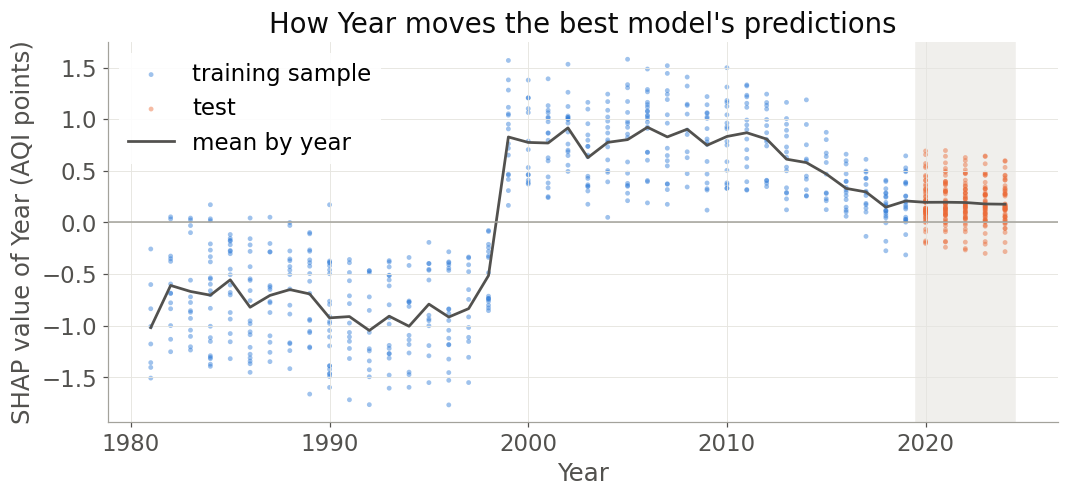

,training sample,test
Non-combustible renewables,1.05,1.24
Natural gas,1.52,0.94
Petroleum,1.08,0.80
Wood and waste,0.63,0.56
Coal,0.51,0.55
State,0.62,0.51
Fuel ethanol,0.23,0.31
Year,0.72,0.22
Biodiesel,0.14,0.11
Nuclear,0.13,0.10


In [49]:
try:
    import shap
except ImportError:
    shap = None
    print("shap is not installed (pip install shap); skipping 7.1b")

if shap is not None:
    pre, forest = best_model.named_steps["pre"], best_model.named_steps["model"]
    shap_names = [n.split("__", 1)[1] for n in pre.get_feature_names_out()]
    shap_train = train.sample(600, random_state=SEED).sort_values(ID_COLS)    # exact TreeSHAP on all 1,944 rows takes minutes
    explainer = shap.TreeExplainer(forest)
    sv_train, sv_test = explainer.shap_values(pre.transform(shap_train)), explainer.shap_values(pre.transform(test))
    base = float(np.ravel(explainer.expected_value)[0])
    print(f"base value (average training prediction): {base:.2f} | base + SHAP values reproduce the test predictions to within "
          f"{np.abs(base + sv_test.sum(axis=1) - test_pred).max():.1e}")

    # 1. Year's contribution by period, and the frozen-after-2019 check
    i_year = shap_names.index("Year")
    year_shap = pd.concat([pd.DataFrame({"Year": shap_train.Year.values, "shap": sv_train[:, i_year], "set": "training sample"}),
                           pd.DataFrame({"Year": test.Year.values, "shap": sv_test[:, i_year], "set": "test"})], ignore_index=True)
    by_period = year_shap.groupby(pd.cut(year_shap.Year, [1980, 1989, 1999, 2009, 2014, 2019, 2024],
                                         labels=["1981-89", "1990-99", "2000-09", "2010-14", "2015-19", "2020-24 (test)"]), observed=True).shap
    print("mean Year SHAP by period (AQI points):", by_period.mean().round(2).to_dict())
    print(f"largest change in any test prediction when its Year is set to 2019: {np.abs(best_model.predict(test.assign(Year=2019)) - test_pred).max():.1e}")

    fig, ax = plt.subplots(figsize=(10, 4.8))
    for name, color in [("training sample", BLUE), ("test", ORANGE)]:
        d = year_shap[year_shap.set == name]
        ax.scatter(d.Year, d.shap, s=10, color=color, alpha=0.45, label=name, edgecolor="none")
    year_means = year_shap.groupby("Year").shap.mean()
    ax.plot(year_means.index, year_means.values, color=INK2, lw=1.8, label="mean by year")
    ax.axhline(0, color=GRAY, lw=1)
    ax.axvspan(TEST_START - 0.5, LAST_YEAR + 0.5, color="#f0efec", zorder=0)
    ax.set(xlabel="Year", ylabel="SHAP value of Year (AQI points)", title="How Year moves the best model's predictions")
    ax.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
    plt.tight_layout(); plt.show()

    # 2. Context: mean |SHAP| by feature group (a group's columns are summed first)
    shap_groups = {"State": [i for i, n in enumerate(shap_names) if n.startswith("State_")], "Year": [i_year],
                   **{k: [shap_names.index(c) for c in cols] for k, cols in by_source.items()}}
    display(pd.DataFrame({g: {"training sample": np.abs(sv_train[:, idx].sum(axis=1)).mean(), "test": np.abs(sv_test[:, idx].sum(axis=1)).mean()}
                          for g, idx in shap_groups.items()}).T.sort_values("test", ascending=False).round(2))

In [50]:
# 1999: PM2.5 becomes a main pollutant across the network (sums over qualifying counties, from the AQI target file)
by_year = aqi_target.groupby("Year")
pollutant_cols = ["Days CO", "Days NO2", "Days Ozone", "Days PM2.5", "Days PM10"]
pd.DataFrame({"PM2.5 share of main-pollutant days": by_year["Days PM2.5"].sum() / by_year[pollutant_cols].sum().sum(axis=1),
              "mean state Median AQI": by_year[TARGET_COL].mean()}).loc[1996:2002].round(3)

,PM2.5 share of main-pollutant days,mean state Median AQI
Year,,
1996,0.008,39.299
1997,0.008,39.304
1998,0.011,40.789
1999,0.177,44.292
2000,0.252,43.567
2001,0.260,44.061
2002,0.269,43.363


**Reading this:**
* SHAP values add up to the model's predictions (largest gap 4e-11), relative to an average training prediction of 42.0 AQI points.
* **Year's effect is a step, not a smooth trend:** about −0.7 through 1998, about +0.8 from 1999 to 2014, falling to about +0.3 in 2015–19. The switch happens between 1998 and 1999.
* **That step matches a monitoring change** (table above): in 1999 PM2.5's share of main-pollutant days jumped from about 1% to 18%, and the average state Median AQI rose about 3.5 points. This fits the EPA's national PM2.5 monitoring rollout (outside knowledge). Since a day's AQI is the highest of the pollutants a county monitors, adding PM2.5 monitors can only raise it, so part of the "Year" effect is a change in measurement, not air quality.
* **After 2019 the effect is frozen:** test-year contributions average 0.19, about the 2019 level, and setting every test row's Year to 2019 changes no prediction. This is why Year's test permutation importance is exactly 0.
* **Size:** Year contributes 0.72 on average in training but only 0.22 on test rows. The largest test contributions come from renewables (1.24), natural gas (0.94) and petroleum (0.80), the same groups that lead the permutation importance.

### 7.2 Ablation
Permutation importance asks whether the *trained* model relies on a group; ablation asks whether a model can do *as well without it* when retrained. A group can matter in the first sense but not the second if other features carry the same information. Each run retrains the best configuration (same hyperparameters) without one group, on the same 5 folds. A positive delta means removing the group hurts, and because the folds are shared, each delta is also compared fold by fold.

In [53]:
def cv_rmse_for(num, cat, model):
    """Per-fold RMSE of the configuration on the forward folds."""
    pipe = make_pipeline(num, cat, clone(model))
    return np.array([root_mean_squared_error(y_train.iloc[va], pipe.fit(train.iloc[tr], y_train.iloc[tr]).predict(train.iloc[va]))
                     for tr, va in FOLDS])

best_estimator = best_model.named_steps["model"]
ablation_groups = {**{f"energy: {k}": v for k, v in by_source.items()},
                   "fuels introduced after 2000": LATE_FUELS,
                   "all energy features": ENERGY,
                   "Year": ["Year"],
                   **{c: [c] for c in BEST_CAT}}
full_scores = cv_rmse_for(BEST_NUM, BEST_CAT, best_estimator)
abl = []
for g, cols in ablation_groups.items():
    s = cv_rmse_for([c for c in BEST_NUM if c not in cols], [c for c in BEST_CAT if c not in cols], best_estimator)
    d = s - full_scores                      # paired: same folds, so fold difficulty cancels out
    abl.append({"removed": g, "n_cols": len(cols), "cv_rmse": pm(s.mean(), s.std()), "delta_vs_full": d.mean(),
                "delta_std": d.std(), "folds_worse": f"{int((d > 0).sum())} of {len(d)}", "per_fold_delta": np.round(d, 2)})
print(f"full model CV RMSE: {pm(full_scores.mean(), full_scores.std())}")
ablation = pd.DataFrame(abl).sort_values("delta_vs_full", ascending=False).reset_index(drop=True)
ablation.round(3)


full model CV RMSE: 3.78 ± 0.56


,removed,n_cols,cv_rmse,delta_vs_full,delta_std,folds_worse,per_fold_delta
0,energy: Natural gas,6,3.91 ± 0.60,0.130,0.108,4 of 5,"[0.1, 0.14, 0.3, 0.15, -0.04]"
1,Year,1,3.90 ± 0.65,0.119,0.218,4 of 5,"[0.02, 0.55, 0.03, -0.02, 0.02]"
2,State,1,3.86 ± 0.58,0.078,0.061,4 of 5,"[0.06, 0.16, 0.08, -0.02, 0.12]"
3,energy: Non-combustible renewables,4,3.86 ± 0.61,0.075,0.121,4 of 5,"[0.03, 0.31, 0.03, -0.04, 0.04]"
4,energy: Coal,5,3.85 ± 0.54,0.067,0.030,5 of 5,"[0.01, 0.08, 0.08, 0.06, 0.1]"
5,energy: Petroleum,6,3.83 ± 0.66,0.046,0.146,4 of 5,"[0.08, 0.14, 0.21, 0.02, -0.22]"
6,energy: Renewable diesel,1,3.81 ± 0.57,0.028,0.041,3 of 5,"[-0.01, 0.09, 0.05, 0.02, -0.02]"
7,energy: Nuclear,1,3.81 ± 0.57,0.027,0.050,2 of 5,"[-0.02, 0.11, 0.06, -0.0, -0.01]"
8,fuels introduced after 2000,4,3.80 ± 0.57,0.024,0.037,5 of 5,"[0.01, 0.1, 0.0, 0.0, 0.01]"
9,energy: Biodiesel,3,3.78 ± 0.58,0.000,0.020,3 of 5,"[0.02, 0.01, 0.02, -0.03, -0.02]"


**Reading this:**
* **No single group matters much.** The largest cost is natural gas (+0.13), small next to the full model's fold-to-fold spread (±0.56).
* **Coal is the only single fuel whose removal hurts in all 5 folds** (+0.07); natural gas hurts in 4 of 5. Both effects are small.
* **Year's cost (+0.12) comes almost entirely from one fold** (+0.55 in 2000–04).
* **Energy and State substitute for each other.** Removing State costs +0.08, and removing all 34 energy features costs nothing on average (−0.05, worse in only 2 of 5 folds): whichever is left supplies much the same information.
* **The post-2000 fuels don't act as a hidden clock** (2.4): removing them changes CV RMSE by only +0.02 (worse in every fold, but by at most 0.1).

### 7.3 Sensitivity analysis
**(a) Hyperparameters.** Do the results depend on the exact settings chosen for the Random Forest? Its grid had `max_depth` (None or 10), `max_features` (0.3, 0.6 or 1.0) and `min_samples_leaf` (1, 5 or 20): 18 combinations, all already scored during tuning. For each value of each hyperparameter, the table shows the best CV RMSE among combinations using that value (a *profile*); the range across a hyperparameter's values shows how much it matters.

In [56]:
cvr = pd.DataFrame(BEST_SEARCH.cv_results_)
same_type = cvr[cvr.param_model.map(lambda m: type(m).__name__) == BEST.model]
profiles = []
for p in [c for c in same_type.columns if c.startswith("param_model__")]:
    key = p.replace("param_", "")
    used = same_type[same_type.params.map(lambda d: key in d)]   # not .notna(): that would also drop max_depth=None
    if used.empty:          # hyperparameter of the other model in this family
        continue
    prof = used.groupby(used[p].astype(str)).agg(best_cv_rmse=("mean_test_rmse", "max"), n_configs=("mean_test_rmse", "size"))
    prof = prof.reindex(sorted(prof.index, key=lambda v: (v == "None", float(v) if v.replace(".", "", 1).isdigit() else 0.0)))
    prof["best_cv_rmse"] = -prof["best_cv_rmse"]
    profiles.append(prof.reset_index().rename(columns={p: "value"}).assign(hyperparameter=p.replace("param_model__", "")))
profiles = pd.concat(profiles)[["hyperparameter", "value", "best_cv_rmse", "n_configs"]]
print("range of best CV RMSE across each hyperparameter's values:")
print(profiles.groupby("hyperparameter")["best_cv_rmse"].agg(lambda s: round(s.max() - s.min(), 3)).to_string())
profiles.round(3)

range of best CV RMSE across each hyperparameter's values:
hyperparameter
max_depth           0.098
max_features        0.037
min_samples_leaf    0.704


,hyperparameter,value,best_cv_rmse,n_configs
0,max_depth,10,3.879,9
1,max_depth,None,3.780,9
0,max_features,0.3,3.818,6
1,max_features,0.6,3.780,6
2,max_features,1.0,3.789,6
0,min_samples_leaf,1,3.780,6
1,min_samples_leaf,5,3.933,6
2,min_samples_leaf,20,4.484,6


**Reading this:**
* **`max_depth` and `max_features` hardly matter:** ranges of 0.10 and 0.04, a small fraction of the fold spread (±0.56). The chosen `max_features` = 0.6 is only 0.01 better than 1.0.
* **`min_samples_leaf` matters a lot:** going from 1 to 20 rows per leaf raises CV RMSE by 0.70. With about 38 training rows per state, large leaves force trees to average across states or distant years, blurring each state's own level; this fits the finding that the model succeeds mainly by learning state levels.
* The chosen `min_samples_leaf` = 1 is a natural limit and can't be extended.

**(b) Training window.** Does older data help, or does it describe a world that no longer exists (different rules, monitors and energy mix)? The best configuration is retrained with training starting in 1980, 1985, …, 2010, and scored two ways: **validation** (train through 2014, predict 2015–19; uses training years only, so it's a fair basis for a decision) and **test** (train through 2019, predict 2020–24). This is also the data-size vs accuracy tradeoff.

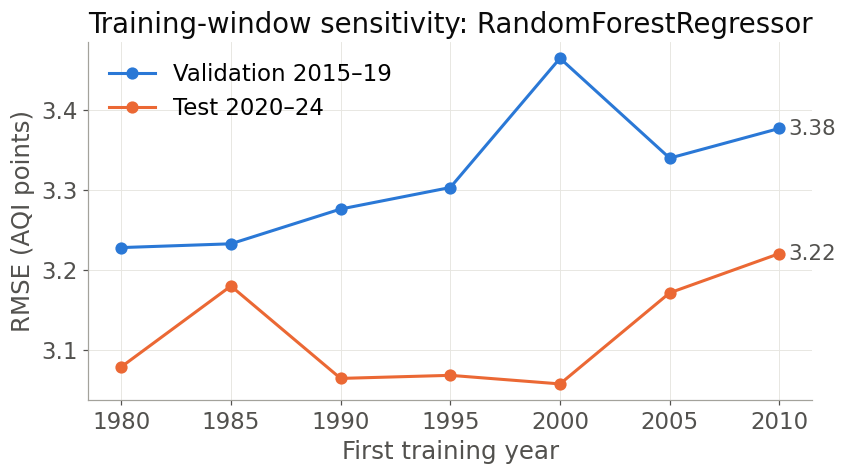

,train_start,train_rows,val_rmse_2015_19,test_rmse_2020_24
0,1980,1944,3.228,3.078
1,1985,1755,3.233,3.180
2,1990,1519,3.276,3.064
3,1995,1270,3.303,3.068
4,2000,1020,3.465,3.057
5,2005,765,3.340,3.171
6,2010,510,3.377,3.220


In [59]:
window_rows = []
for start in [1980, 1985, 1990, 1995, 2000, 2005, 2010]:
    fit_v = train[(train.Year >= start) & (train.Year < 2015)]
    val = train[train.Year >= 2015]
    fit_t = train[train.Year >= start]
    pv = make_pipeline(BEST_NUM, BEST_CAT, clone(best_estimator)).fit(fit_v, fit_v[TARGET_COL]).predict(val)
    pt = make_pipeline(BEST_NUM, BEST_CAT, clone(best_estimator)).fit(fit_t, fit_t[TARGET_COL]).predict(test)
    window_rows.append({"train_start": start, "train_rows": len(fit_t),
                        "val_rmse_2015_19": root_mean_squared_error(val[TARGET_COL], pv),
                        "test_rmse_2020_24": root_mean_squared_error(y_test, pt)})
window = pd.DataFrame(window_rows)

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(window.train_start, window.val_rmse_2015_19, color=BLUE, lw=2, marker="o", ms=7, label="Validation 2015–19")
ax.plot(window.train_start, window.test_rmse_2020_24, color=ORANGE, lw=2, marker="o", ms=7, label="Test 2020–24")
for col, c in [("val_rmse_2015_19", BLUE), ("test_rmse_2020_24", ORANGE)]:
    ax.annotate(f"{window[col].iloc[-1]:.2f}", (window.train_start.iloc[-1], window[col].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", color=INK2, fontsize=14)
ax.set(xlabel="First training year", ylabel="RMSE (AQI points)", title=f"Training-window sensitivity: {BEST.model}")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()
window.round(3)

**Reading this:**
* **Validation favors keeping all years:** starting in 1980 gives the best validation RMSE (3.23). Starting in 1985–1995 costs under 0.1; starting in 2000 or later costs 0.11–0.24.
* **On test the differences are small and noisy:** 3.06–3.22 across all start years, with 2000 marginally best (3.06 against 3.08 for 1980).
* So there's no reason to drop the early years.

**(c) Preprocessing threshold.** Does the near-duplicate cut-off (|r| ≥ 0.98, section 2.4) matter? The best configuration is re-scored with cut-offs of 0.90 and 0.95 and with no cut-off.

In [62]:
# Rebuild the energy features before the column rules, then re-apply the rules with different thresholds
pre_rules = combine_renewables(seds_raw[seds_raw.Year.between(FIRST_YEAR, LAST_YEAR)], seds_categories)
pre_rules[energy_columns(pre_rules)] = np.log1p(pre_rules[energy_columns(pre_rules)].div(pre_rules[POP_COL], axis=0))
full = df.drop(columns=ENERGY).merge(pre_rules.drop(columns=[POP_COL, CLUSTER_COL]), on=ID_COLS, how="left")
full_train = full[full.Year < TEST_START].reset_index(drop=True)
assert (full_train.Year.values == train.Year.values).all() and (full_train.State.values == train.State.values).all()

thr_rows = []
for thr in [0.90, 0.95, 0.98, 1.01]:   # 1.01 = keep all near-duplicates
    drop_t = fit_column_rules(full_train[ID_COLS + energy_columns(pre_rules)], corr_threshold=thr)
    energy_t = [c for c in energy_columns(pre_rules) if c not in drop_t]
    num_t = energy_t + [c for c in BEST_NUM if c not in ENERGY]
    scores = [root_mean_squared_error(full_train[TARGET_COL].iloc[va],
                                      make_pipeline(num_t, BEST_CAT, clone(best_estimator)).fit(full_train.iloc[tr], full_train[TARGET_COL].iloc[tr]).predict(full_train.iloc[va]))
              for tr, va in FOLDS]
    thr_rows.append({"corr_threshold": "none" if thr > 1 else thr, "n_energy_features": len(energy_t), "cv_rmse": pm(np.mean(scores), np.std(scores))})
pd.DataFrame(thr_rows)

,corr_threshold,n_energy_features,cv_rmse
0,0.9,33,3.76 ± 0.56
1,0.95,34,3.78 ± 0.56
2,0.98,34,3.78 ± 0.56
3,none,36,3.78 ± 0.57


**Reading this:** CV RMSE stays between 3.76 and 3.78 for every cut-off. Only two or three near-copy columns are ever affected, so the choice doesn't matter.

### 7.4 Tradeoffs
The best model from each explanatory family, compared on accuracy, fit time, interpretability and whether it can extend a time trend past 2019. The last two columns are judgments, not measurements.

In [65]:
trade = best_explanatory[["family", "model", "feature_set", "cv_rmse_mean", "cv_rmse_std", "fit_seconds"]].merge(
    test_table.query("framing == 'explanatory'")[["family", "test_rmse"]], on="family")
trade["interpretability"] = trade.family.map({"Linear (Ridge/Lasso/ElasticNet)": "high: signed coefficients",
                                              "Tree ensemble (RF/HGB)": "medium: importances, no direction",
                                              "Instance-based (KNN)": "medium: neighbours can be shown",
                                              "Kernel (SVR)": "low"})
trade["extrapolates Year trend"] = trade.family.map({"Linear (Ridge/Lasso/ElasticNet)": "yes (linear)", "Tree ensemble (RF/HGB)": "no (flat past 2019)",
                                                     "Instance-based (KNN)": "no", "Kernel (SVR)": "no (RBF decays)"})
trade.round(3)

,family,model,feature_set,cv_rmse_mean,cv_rmse_std,fit_seconds,test_rmse,interpretability,extrapolates Year trend
0,Tree ensemble (RF/HGB),RandomForestRegressor,energy+state,3.780,0.562,2.454,3.078,"medium: importances, no direction",no (flat past 2019)
1,Instance-based (KNN),KNeighborsRegressor,energy,4.561,1.195,0.003,3.125,medium: neighbours can be shown,no
2,Kernel (SVR),SVR,energy+state,4.954,1.105,0.026,3.991,low,no (RBF decays)
3,Linear (Ridge/Lasso/ElasticNet),ElasticNet,energy+cluster,5.662,0.978,0.005,5.157,high: signed coefficients,yes (linear)


In [66]:
fx = test_table.set_index(["framing", "family"])
best_fc = best_forecast.iloc[0]
print(f"Accuracy vs question asked: best explanatory test RMSE {fx.loc[('explanatory', BEST.family), 'test_rmse']:.2f} "
      f"vs best forecasting test RMSE {fx.loc[('forecasting', best_fc.family), 'test_rmse']:.2f} "
      f"({best_fc.model}); the forecasting model needs last year's AQI, so it no longer answers 'AQI from energy'.")
print(f"Data size vs accuracy: best training start by validation = {int(window.loc[window.val_rmse_2015_19.idxmin(), 'train_start'])}, "
      f"by test = {int(window.loc[window.test_rmse_2020_24.idxmin(), 'train_start'])} (full window starts 1981 after the lag drop).")

Accuracy vs question asked: best explanatory test RMSE 3.08 vs best forecasting test RMSE 2.66 (Lasso); the forecasting model needs last year's AQI, so it no longer answers 'AQI from energy'.
Data size vs accuracy: best training start by validation = 1980, by test = 2000 (full window starts 1981 after the lag drop).


**Reading this:**
* **Accuracy vs interpretability:** the most accurate model (Random Forest, CV 3.78) can say which features it uses but not in which direction; the most interpretable (linear, signed coefficients) is the least accurate (5.66).
* **Accuracy vs the question asked:** adding last year's AQI cuts test error from 3.08 to 2.66, but the model then mostly learns "AQI stays near last year's value" rather than answering the energy question.
* **Accuracy vs extrapolation:** trees, KNN and RBF SVR can't extend a trend past 2019; the linear models can, but that doesn't help them here.
* **Data size vs accuracy:** more history helps on validation (7.3b).
* **Speed** isn't a real constraint: the Random Forest is by far the slowest to fit (`fit_seconds`), but the whole tuning takes minutes.

## 8. Failure analysis
### 8.1 Largest errors
The best model's largest test errors, each tagged by three rules:
* **sudden change:** AQI moved from the previous year by more than twice the typical training year-to-year change (median 1.75 points);
* **thin monitoring:** the state-year rests on 3 or fewer qualifying counties;
* **stale state level:** the state's errors have the same sign in every test year, so the model's idea of that state's level is out of date.

These rules describe *what* went wrong. Sections 8.2–8.4 look at *why*, using three states whose failures have different causes.

In [69]:
typical_change = (train[TARGET_COL] - train["AQI_lag1"]).abs().median()
fail = err.assign(abs_error=lambda d: d.residual.abs(),
                  change_vs_prev_year=lambda d: d[TARGET_COL] - d.AQI_lag1)
fail = fail.merge(by_state[["same_sign_all_years"]], left_on="State", right_index=True)
fail["sudden_change"] = fail.change_vs_prev_year.abs() > 2 * typical_change
fail["thin_monitoring"] = fail.n_counties <= 3
fail["stale_state_level"] = fail.same_sign_all_years
fail["categories"] = fail.apply(lambda r: ", ".join(k for k in ["sudden_change", "thin_monitoring", "stale_state_level"] if r[k]) or "none", axis=1)
print(f"typical |year-to-year change| in training (median): {typical_change:.2f} AQI points")
fail["persistence_pred"] = fail.State.map(train.sort_values("Year").groupby("State")[TARGET_COL].apply(lambda s: s.tail(3).mean()))
worst = fail.sort_values("abs_error", ascending=False).head(10)
worst[["State", "Year", TARGET_COL, "pred", "persistence_pred", "residual", "AQI_lag1", "change_vs_prev_year", "n_counties", "categories"]].round(2)

typical |year-to-year change| in training (median): 1.75 AQI points


,State,Year,Median AQI,pred,persistence_pred,residual,AQI_lag1,change_vs_prev_year,n_counties,categories
147,NE,2022,29.26,40.59,41.22,-11.34,37.21,-7.95,8,"sudden_change, stale_state_level"
134,MT,2024,27.97,38.26,38.81,-10.28,34.36,-6.39,19,sudden_change
55,HI,2020,21.76,31.78,28.99,-10.01,21.26,0.50,4,stale_state_level
56,HI,2021,23.26,32.21,28.99,-8.95,21.76,1.49,4,stale_state_level
59,HI,2024,24.34,32.35,28.99,-8.01,24.74,-0.41,3,"thin_monitoring, stale_state_level"
35,DC,2020,44.00,51.60,52.33,-7.60,49.00,-5.00,1,"sudden_change, thin_monitoring, stale_state_level"
16,AZ,2021,50.49,43.30,44.33,7.19,48.64,1.86,13,stale_state_level
63,IA,2023,49.55,42.46,46.58,7.09,43.71,5.83,12,sudden_change
39,DC,2024,45.00,52.09,52.33,-7.09,50.00,-5.00,1,"sudden_change, thin_monitoring, stale_state_level"
183,OK,2023,48.12,41.29,43.72,6.83,46.21,1.90,20,stale_state_level


In [70]:
print("share of all test rows in each category:")
print(fail[["sudden_change", "thin_monitoring", "stale_state_level"]].mean().round(3).to_string())
print("\nmean |error| by category flag:")
for k in ["sudden_change", "thin_monitoring", "stale_state_level"]:
    print(f"  {k:18s} flagged={fail.loc[fail[k], 'abs_error'].mean():.2f}  not flagged={fail.loc[~fail[k], 'abs_error'].mean():.2f}")

share of all test rows in each category:
sudden_change        0.208
thin_monitoring      0.090
stale_state_level    0.333

mean |error| by category flag:
  sudden_change      flagged=3.46  not flagged=2.02
  thin_monitoring    flagged=3.06  not flagged=2.24
  stale_state_level  flagged=3.36  not flagged=1.79


**Reading this:** flagged rows have larger errors for all three rules (mean absolute error 3.46 vs 2.02 for sudden change, 3.06 vs 2.24 for thin monitoring, 3.36 vs 1.79 for a stale level). A third of test rows belong to states with a stale level.

### 8.2 Three failures with different causes
* **Nebraska: a monitoring network change** (data artifact). New, lower-reading counties began to qualify during the test period, lowering the state value (8.4).
* **Hawaii: an omitted pollution source** (missing variable). Most training years were inflated by a non-energy source the model can't see, so it learned the wrong level (8.3).
* **Rhode Island: a one-off event, amplified by thin monitoring** (temporary shock). An unusual 2023 rose sharply and 2024 fell back; with only three counties, nothing dilutes the swing. A regional smoke episode is a plausible cause (outside knowledge, not checked here).

The chart shows each state's actual AQI, the model's test predictions, and the number of qualifying counties (right axis).

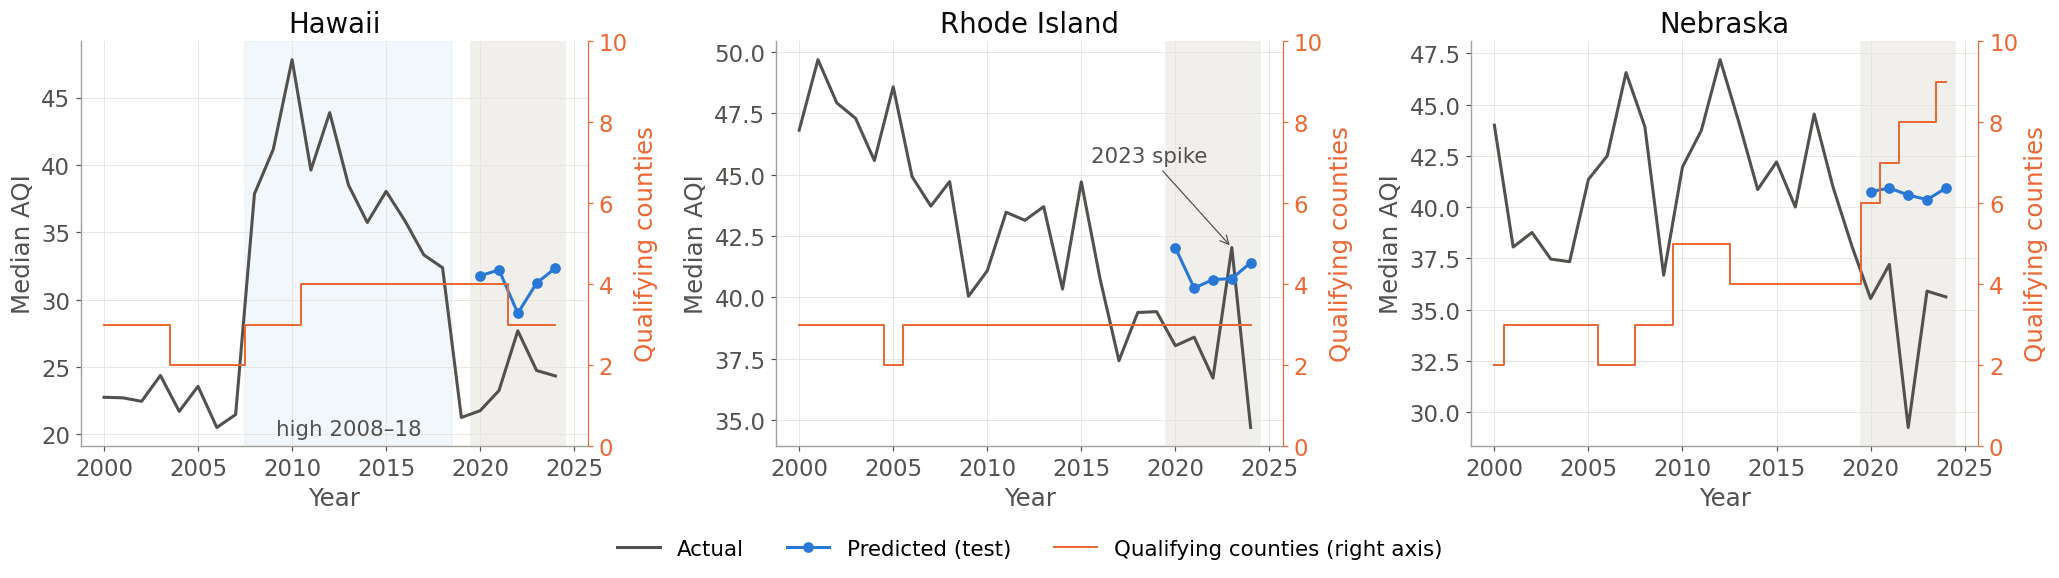

In [72]:
# Three failures with different causes: each state's AQI history, the model's test predictions, and its qualifying counties
cases = {"HI": "Hawaii", "RI": "Rhode Island", "NE": "Nebraska"}

fig, axes = plt.subplots(1, len(cases), figsize=(19, 5.4))
for ax, (st, name) in zip(axes, cases.items()):
    hist = df[(df.State == st) & (df.Year >= 2000)]
    tp = err[err.State == st]
    ax.axvspan(TEST_START - 0.5, LAST_YEAR + 0.5, color="#f0efec", zorder=0)
    ax.plot(hist.Year, hist[TARGET_COL], color=INK2, lw=2, label="Actual")
    ax.plot(tp.Year, tp.pred, color=BLUE, lw=2, marker="o", ms=6, label="Predicted (test)")
    ax.set(title=name, xlabel="Year", ylabel="Median AQI")
    ax.xaxis.set_major_locator(plt.MultipleLocator(5))

    ax2 = ax.twinx()                                   # number of qualifying counties behind each state value
    ax2.step(hist.Year, hist.n_counties, where="mid", color=ORANGE, lw=1.3, label="Qualifying counties (right axis)")
    ax2.set_ylim(0, max(10, hist.n_counties.max() + 1))
    ax2.set_ylabel("Qualifying counties", color=ORANGE)
    ax2.tick_params(axis="y", colors=ORANGE)
    ax2.spines["right"].set_visible(True); ax2.spines["right"].set_color(ORANGE)
    ax2.grid(False)

    if st == "HI":
        ax.axvspan(2007.5, 2018.5, color=BLUE, alpha=0.06, zorder=0)
        lo = ax.get_ylim()[0]
        ax.text(2013, lo + 0.5, "high 2008–18", ha="center", va="bottom", color=INK2, fontsize=14)
    if st == "RI":
        spike = hist.loc[hist.Year == 2023, TARGET_COL].iloc[0]
        ax.annotate("2023 spike", (2023, spike), xytext=(2015.5, spike + 3.5), color=INK2, fontsize=14,
                    arrowprops={"arrowstyle": "->", "color": INK2, "lw": 0.8})

handles = axes[0].get_legend_handles_labels()[0] + ax2.get_lines()[:1]
fig.legend(handles, [h.get_label() for h in handles], frameon=False, loc="lower center", ncol=3, fontsize=14)
plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

### 8.3 Hawaii: an omitted pollution source
**Hypothesis:** volcanic smog ("vog") from Kīlauea's 2008–2018 summit eruption raised Hawaii's AQI during most of the training period, and energy data can't see it. If so, the target should jump around 2008 and fall back around 2019, with PM2.5 (vog forms sulfate particles) as the main pollutant. The eruption dates are outside knowledge, not something this data shows.

In [74]:
hi = aqi_target[(aqi_target.State == "HI") & aqi_target.Year.between(2003, 2024)].set_index("Year")[TARGET_COL]
pollutant_days = aqi_target[aqi_target.State == "HI"].set_index("Year")[["Days Ozone", "Days PM2.5", "Days PM10", "Days NO2", "Days CO"]]
hawaii = hi.to_frame().join(pollutant_days).assign(pm25_share=lambda d: d["Days PM2.5"] / d[["Days Ozone", "Days PM2.5", "Days PM10", "Days NO2", "Days CO"]].sum(axis=1))
periods = {"2003-2007": (2003, 2007), "2008-2018": (2008, 2018), "2019-2024": (2019, 2024)}
print("Hawaii mean Median AQI by period:", {k: round(hi.loc[a:b].mean(), 1) for k, (a, b) in periods.items()})
print("mean of the 3 training years the persistence baseline uses (2017-2019):", round(hi.loc[2017:2019].mean(), 1))
hawaii.round(2)


Hawaii mean Median AQI by period: {'2003-2007': 22.3, '2008-2018': 38.6, '2019-2024': 23.8}
mean of the 3 training years the persistence baseline uses (2017-2019): 29.0


,Median AQI,Days Ozone,Days PM2.5,Days PM10,Days NO2,Days CO,pm25_share
Year,,,,,,,
2003,24.38,430,353,267,9,4,0.33
2004,21.71,151,277,250,1,11,0.40
2005,23.57,156,221,319,12,2,0.31
2006,20.51,130,166,359,36,20,0.23
2007,21.48,114,162,382,37,5,0.23
2008,37.85,174,493,341,16,0,0.48
2009,41.15,49,1025,13,1,0,0.94
2010,47.81,45,1020,7,1,0,0.95
2011,39.61,45,1230,2,42,5,0.93


**Reading this:** Hawaii averaged 22.3 in 2003–07, 38.6 in 2008–18 and 23.8 in 2019–24, with PM2.5 the main pollutant from 2009, consistent with the hypothesis. Even the persistence baseline (29.0, the 2017–19 average) sits above the test-period values. One caveat: the main-pollutant mix also changed in 2009, when PM10 almost stopped being the main pollutant, so a change in which monitors operate could explain part of the 2008 jump. The drop in 2019, while PM2.5 stays the main pollutant, fits the eruption ending better than a monitor change.

### 8.4 Nebraska: a monitoring network change
Nebraska is over-predicted in every test year while its number of qualifying counties grows. If the new counties caused that, rebuilding Nebraska's value **without the counties that first qualified during the test period** should remove most of the error. Those counties barely affect the training years, so the model's predictions stay essentially the same. This uses the county file with the same rules as `AQI_Cleaning.ipynb`, and also shows where each new county was before it qualified: in the EPA file with fewer than 180 days (removed by the coverage rule), or absent.

In [77]:
# Nebraska: state value from all qualifying counties vs without the counties that first qualified in the test period
aqi_county = load_file("AQI_merged.csv", "AQI", index_col=0)
ne_all = aqi_county[aqi_county.State == "Nebraska"]
ne_q = ne_all[(ne_all["Days with AQI"] >= 180) & ((ne_all["Days Ozone"] + ne_all["Days PM2.5"]) > 0)]     # same rules as AQI_Cleaning.ipynb
fixed = set(ne_q.loc[ne_q.Year == TEST_START - 1, "County"])
newcomers = sorted(set(ne_q.loc[ne_q.Year >= TEST_START, "County"]) - fixed)
print("counties qualifying in", TEST_START - 1, ":", sorted(fixed), "| joined later:", newcomers)

# Where each newcomer was before it qualified: short coverage (filtered out) or not in the EPA file
first_q = ne_q[ne_q.County.isin(newcomers) & (ne_q.Year >= TEST_START)].groupby("County").Year.min()
before = ne_all[ne_all.County.isin(newcomers) & ne_all.Year.between(2010, TEST_START - 1)].groupby("County")["Days with AQI"]
display(pd.DataFrame({"first qualifying year": first_q, "years in EPA file 2010-19": before.size(),
                      "median days with AQI 2010-19": before.median()}).reindex(newcomers).fillna({"years in EPA file 2010-19": 0}))

def weighted(rows):
    return (rows[TARGET_COL] * rows["Days with AQI"]).sum() / rows["Days with AQI"].sum()
without = ne_q[~ne_q.County.isin(newcomers)]
ne_cmp = pd.DataFrame({"target (all qualifying)": ne_q.groupby("Year").apply(weighted),
                       "without newcomers": without.groupby("Year").apply(weighted),
                       "counties (all)": ne_q.groupby("Year").County.nunique(),
                       "counties (without newcomers)": without.groupby("Year").County.nunique()})
print(f"largest change in any training year: "
      f"{(ne_cmp.iloc[:, 1] - ne_cmp.iloc[:, 0]).loc[:TEST_START - 1].abs().max():.2f} AQI points")

# Model errors against both versions, using the model's own test predictions
ne_err = err[err.State == "NE"].set_index("Year")[["pred"]].join(ne_cmp)
ne_err["error vs target"] = ne_err["target (all qualifying)"] - ne_err.pred
ne_err["error without newcomers"] = ne_err["without newcomers"] - ne_err.pred
print(f"mean test error: {ne_err['error vs target'].mean():+.2f} vs target, {ne_err['error without newcomers'].mean():+.2f} without the newcomers | "
      f"RMSE {np.sqrt((ne_err['error vs target'] ** 2).mean()):.2f} vs {np.sqrt((ne_err['error without newcomers'] ** 2).mean()):.2f}")
ne_err.round(2)

counties qualifying in 2019 : ['Douglas', 'Knox', 'Lancaster', 'Sarpy'] | joined later: ['Gage', 'Hall', 'Scotts Bluff', 'Sioux', 'Washington']


,first qualifying year,years in EPA file 2010-19,median days with AQI 2010-19
County,,,
Gage,2021,0.0,NaN
Hall,2020,10.0,113.5
Scotts Bluff,2020,10.0,113.0
Sioux,2024,0.0,NaN
Washington,2022,10.0,116.0


largest change in any training year: 0.17 AQI points
mean test error: -6.01 vs target, -1.61 without the newcomers | RMSE 6.60 vs 2.28


,pred,target (all qualifying),without newcomers,counties (all),counties (without newcomers),error vs target,error without newcomers
Year,,,,,,,
2020,40.76,35.55,37.88,6,4,-5.21,-2.88
2021,40.93,37.21,39.65,7,4,-3.72,-1.29
2022,40.59,29.26,36.85,8,4,-11.34,-3.74
2023,40.37,35.91,41.32,8,4,-4.46,0.95
2024,40.93,35.63,39.82,9,4,-5.30,-1.11


**Reading this:**
* Three of the five new counties (Hall, Scotts Bluff, Washington) were in the EPA file every year from 2010 to 2019, but with only about 113–116 days a year, so the 180-day rule removed them; they qualified once they reported most days (2020–2022). Gage and Sioux had no data in 2010–2019.
* Removing them changes the training years by at most 0.17, so the predictions would be essentially the same.
* Without them, Nebraska's mean test error falls from −6.0 to −1.6 and its RMSE from 6.6 to 2.3; the worst miss (2022) shrinks from −11.3 to −3.7. 2022 remains the lowest test year (36.9), so part of that dip is real.
* So most of Nebraska's failure comes from **which counties are measured**, not from a change in air quality. A target built from a fixed set of counties would avoid this (not implemented).

## 9. Summary of results (generated from the outputs above)

In [80]:
pers = test_table.set_index("family").loc[p_name]
top_source = imp_source.iloc[0]
top_ablation = ablation.iloc[0]
lines = [
    f"Best explanatory model: {BEST.model} ({BEST.family}) using '{BEST.feature_set}': CV RMSE {pm(BEST.cv_rmse_mean, BEST.cv_rmse_std)}, "
    f"test RMSE {root_mean_squared_error(y_test, test_pred):.2f}, test R² {r2_score(y_test, test_pred):.3f}.",
    f"Persistence baseline (state's last 3 years): CV RMSE {pers.cv_rmse:.2f}, test RMSE {pers.test_rmse:.2f}.",
    f"Best forecasting model (adds last year's AQI): {best_fc.model}: CV RMSE {pm(best_fc.cv_rmse_mean, best_fc.cv_rmse_std)}, "
    f"test RMSE {fx.loc[('forecasting', best_fc.family), 'test_rmse']:.2f}.",
    f"Best feature set per family (explanatory): " + "; ".join(f"{r.family} -> {r.feature_set}" for _, r in best_explanatory.iterrows()) + ".",
    f"Most important group (test permutation): {top_source.group} (+{top_source.rmse_increase:.2f} RMSE when shuffled).",
    f"Ablation with the largest CV cost: removing {top_ablation.removed} (Δ CV RMSE {top_ablation.delta_vs_full:+.2f}).",
    f"Training window: best start year by validation {int(window.loc[window.val_rmse_2015_19.idxmin(), 'train_start'])}.",
]
if len(best_reference):
    ref = best_reference.iloc[0]
    ref_test = test_table[(test_table.framing == "reference") & (test_table.family == ref.family)].test_rmse.iloc[0]
    lines.append(f"Reference without energy ({ref.family}, State + Year): CV RMSE {pm(ref.cv_rmse_mean, ref.cv_rmse_std)}, test RMSE {ref_test:.2f}.")
print("\n".join("- " + l for l in lines))

- Best explanatory model: RandomForestRegressor (Tree ensemble (RF/HGB)) using 'energy+state': CV RMSE 3.78 ± 0.56, test RMSE 3.08, test R² 0.652.
- Persistence baseline (state's last 3 years): CV RMSE 3.97, test RMSE 2.69.
- Best forecasting model (adds last year's AQI): Lasso: CV RMSE 2.87 ± 0.53, test RMSE 2.66.
- Best feature set per family (explanatory): Tree ensemble (RF/HGB) -> energy+state; Instance-based (KNN) -> energy; Kernel (SVR) -> energy+state; Linear (Ridge/Lasso/ElasticNet) -> energy+cluster.
- Most important group (test permutation): Natural gas (+1.19 RMSE when shuffled).
- Ablation with the largest CV cost: removing energy: Natural gas (Δ CV RMSE +0.13).
- Training window: best start year by validation 1980.
- Reference without energy (Instance-based (KNN), State + Year): CV RMSE 3.68 ± 0.60, test RMSE 2.44.
